# Computational Linear Algebra: PCA Homework

## Exercise 0.0: Initialization
Fill the missing values in this text box. **Remove the information of the second student if you are not working in a team**.

**Academic Year:** 2025/2026

### Team Members (Alphabetical Order):
1. Provenzano, Davide (S360754);
2. Solimando, Vincenzo (S349147).

Now, fill the python list below with the Student IDs of the team

In [1]:
StudentIDs = [360754,349147]  # <-------- Fill this list with Student IDs of the team

## Exercise 0.1: Starting Code-Cell 

Download the .csv files from the web page of the course (*responses_hw.csv* and *columns_hw.csv*) and past them in **the same folder of this notebook**.


Then, run the cell below, **without modifing any line of code**.

The output of this code cell is **your personal subset of the original dataset**, with 2/3 of the original features (i.e., columns) and 3/4 of the original persons (i.e., rows).

### ATTENTION: DO NOT CHANGE THE CODE INSIDE THE FOLLOWING CELL, ANY CHANGE CAN INVALIDATE THE HOMEWORK!

In [2]:
####################################################################
############## DO NOT CHANGE THE CODE IN THIS CELL #################
####################################################################

import numpy as np
import pandas as pd
from IPython.display import display

var_entertainment_feat_types = ['Interests', 'Movies', 'Music']
var_personal_feat_types = ['Finance', 'Phobias']
fixed_feat_types = ['Personality', 'Health']

label_types = ['Demographic']

variables_by_type = {
    'Demographics': ['Age', 'Height', 'Weight', 'Number of siblings', 
                     'Gender', 'Hand', 'Education', 'Only child', 'Home Town Type',
                     'Home Type'],
    'Finance': ['Finances', 'Shopping centres', 'Branded clothing', 
                'Entertainment spending', 'Spending on looks', 
                'Spending on gadgets', 'Spending on healthy eating'],
    'Health': ['Smoking', 'Alcohol', 'Healthy eating'],
    'Interests': ['History', 'Psychology', 'Politics', 'Mathematics', 
                  'Physics', 'Internet', 'PC', 'Economy Management', 
                  'Biology', 'Chemistry', 'Reading', 'Geography', 
                  'Foreign languages', 'Medicine', 'Law', 'Cars', 
                  'Art exhibitions', 'Religion', 'Countryside, outdoors', 
                  'Dancing', 'Musical instruments', 'Writing', 'Passive sport', 
                  'Active sport', 'Gardening', 'Celebrities', 'Shopping', 
                  'Science and technology', 'Theatre', 'Fun with friends', 
                  'Adrenaline sports', 'Pets'],
    'Movies': ['Movies', 'Horror', 'Thriller', 'Comedy', 'Romantic', 
               'Sci-fi', 'War', 'Fantasy/Fairy tales', 'Animated', 
               'Documentary', 'Western', 'Action'],
    'Music': ['Music', 'Slow songs or fast songs', 'Dance', 'Folk', 
              'Country', 'Classical music', 'Musical', 'Pop', 'Rock', 
              'Metal or Hardrock', 'Punk', 'Hiphop, Rap', 'Reggae, Ska', 
              'Swing, Jazz', 'Rock n roll', 'Alternative', 'Latino', 
              'Techno, Trance', 'Opera'],
    'Personality': ['Daily events', 'Prioritising workload', 
                    'Writing notes', 'Workaholism', 'Thinking ahead', 
                    'Final judgement', 'Reliability', 'Keeping promises', 
                    'Loss of interest', 'Friends versus money', 'Funniness', 
                    'Fake', 'Criminal damage', 'Decision making', 'Elections', 
                    'Self-criticism', 'Judgment calls', 'Hypochondria', 
                    'Empathy', 'Eating to survive', 'Giving', 
                    'Compassion to animals', 'Borrowed stuff', 
                    'Loneliness', 'Cheating in school', 'Health', 
                    'Changing the past', 'God', 'Dreams', 'Charity', 
                    'Number of friends', 'Punctuality', 'Lying', 'Waiting', 
                    'New environment', 'Mood swings', 'Appearence and gestures', 
                    'Socializing', 'Achievements', 'Responding to a serious letter', 
                    'Children', 'Assertiveness', 'Getting angry', 
                    'Knowing the right people', 'Public speaking', 
                    'Unpopularity', 'Life struggles', 'Happiness in life', 
                    'Energy levels', 'Small - big dogs', 'Personality', 
                    'Finding lost valuables', 'Getting up', 'Interests or hobbies', 
                    "Parents' advice", 'Questionnaires or polls', 'Internet usage'],
    'Phobias': ['Flying', 'Storm', 'Darkness', 'Heights', 'Spiders', 'Snakes', 
                'Rats', 'Ageing', 'Dangerous dogs', 'Fear of public speaking']
}

labels = variables_by_type['Demographics']
features_all = []
for tt in variables_by_type.keys():
    if tt != 'Demographics':
        features_all += variables_by_type[tt]

def which_features(*StudentIDs):
    random_seed = min(StudentIDs)
    np.random.seed(random_seed)
    features_ = np.random.choice(features_all, int((2 * len(features_all)) / 3), replace=False).tolist()
    features = []
    features_by_type = {tt: [] for tt in variables_by_type.keys() if tt != 'Demographics'}
    for tt in variables_by_type.keys():
        ft_list = variables_by_type[tt]
        for ii in range(len(ft_list)):
            if ft_list[ii] in features_:
                features.append(ft_list[ii])
                features_by_type[tt].append(ft_list[ii])

    return features, features_by_type

features, features_by_type = which_features(*StudentIDs)

print(f'*** THESE ARE THE {len(features)} SELECTED FEATURES (SEE VARIABLE features):')
for ff in features:
    print(f'{ff}')
print('*************************************')
print('')
print('*** SELECTED FEATURES BY TYPES (SEE VARIABLE features_by_type):')
for tt in features_by_type.keys():
    print(f'{tt}: {features_by_type[tt]}')
    print('')
print('*************************************')
print('')
print('*** THESE ARE THE LABELS (SEE VARIABLE labels):')
for ll in labels:
    print(f'{ll}')
print('*************************************')

def which_rows(df, frac, *StudentIDs):
    random_seed = min(StudentIDs)
    df_ = df.sample(frac=frac, random_state=random_seed)
    return df_

responses_hw = pd.read_csv('responses_hw.csv', index_col=0)
responses = which_rows(responses_hw, 0.75, *StudentIDs)
responses = responses.loc[:, features + labels]

responses_ft = responses.loc[:, features]
responses_lb = responses.loc[:, labels]

print('')
print('*** THIS IS YOUR PERSONAL DATASET (features AND labels TOGETHER, SEE VARIABLE responses)')
display(responses)
print('')
print('*** THIS IS YOUR PERSONAL DATASET (features, SEE VARIABLE responses_ft)')
display(responses_ft)
print('')
print('*** THIS IS YOUR PERSONAL DATASET (labels, SEE VARIABLE responses_lb)')
display(responses_lb)

random_seed = min(StudentIDs)
np.random.seed(random_seed)

your_scaler = np.random.choice(['StandardScaler', 'MinMaxScaler'])


*** THESE ARE THE 93 SELECTED FEATURES (SEE VARIABLE features):
Finances
Entertainment spending
Spending on looks
Healthy eating
History
Psychology
Politics
Mathematics
Physics
Internet
PC
Economy Management
Biology
Reading
Medicine
Religion
Countryside, outdoors
Dancing
Musical instruments
Writing
Passive sport
Active sport
Gardening
Science and technology
Fun with friends
Movies
Horror
Thriller
Romantic
Sci-fi
War
Fantasy/Fairy tales
Animated
Western
Slow songs or fast songs
Folk
Country
Classical music
Reggae, Ska
Swing, Jazz
Rock n roll
Alternative
Latino
Techno, Trance
Opera
Prioritising workload
Writing notes
Thinking ahead
Final judgement
Reliability
Loss of interest
Funniness
Fake
Criminal damage
Decision making
Elections
Self-criticism
Hypochondria
Empathy
Compassion to animals
Cheating in school
Health
Changing the past
God
Dreams
Number of friends
Punctuality
Lying
Waiting
Mood swings
Socializing
Achievements
Responding to a serious letter
Children
Assertiveness
Getting angr

,Finances,Entertainment spending,Spending on looks,Healthy eating,History,Psychology,Politics,Mathematics,Physics,Internet,...,Age,Height,Weight,Number of siblings,Gender,Hand,Education,Only child,Home Town Type,Home Type
109,4,3,3,3,3,4,3,4,4,5,...,20,165,55,3,male,right,secondary school,no,village,house/bungalow
552,1,5,5,4,5,1,1,1,1,5,...,17,175,60,1,female,right,secondary school,no,city,block of flats
320,2,2,4,3,1,4,2,3,1,5,...,19,185,70,1,male,right,secondary school,no,city,block of flats
631,3,4,4,3,4,1,4,2,1,4,...,17,170,50,3,female,right,secondary school,no,city,house/bungalow
498,3,2,2,4,5,4,5,3,2,5,...,19,170,63,0,female,right,secondary school,yes,village,block of flats
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
133,3,1,2,3,2,5,2,5,2,3,...,19,167,55,2,female,right,secondary school,no,city,block of flats
598,4,3,2,2,4,4,3,1,1,5,...,19,168,57,2,female,right,secondary school,no,village,house/bungalow
137,5,3,5,3,3,3,2,1,1,5,...,18,158,65,2,female,right,secondary school,no,city,block of flats
627,4,1,2,2,3,2,2,1,1,4,...,19,153,44,0,female,right,secondary school,yes,city,block of flats



*** THIS IS YOUR PERSONAL DATASET (features, SEE VARIABLE responses_ft)


,Finances,Entertainment spending,Spending on looks,Healthy eating,History,Psychology,Politics,Mathematics,Physics,Internet,...,Questionnaires or polls,Internet usage,Flying,Storm,Darkness,Heights,Rats,Ageing,Dangerous dogs,Fear of public speaking
109,4,3,3,3,3,4,3,4,4,5,...,3,few hours a day,1,2,2,3,2,2,4,3
552,1,5,5,4,5,1,1,1,1,5,...,1,few hours a day,5,3,2,4,2,3,4,4
320,2,2,4,3,1,4,2,3,1,5,...,2,few hours a day,2,1,2,4,3,1,3,4
631,3,4,4,3,4,1,4,2,1,4,...,3,few hours a day,1,2,2,1,5,3,4,2
498,3,2,2,4,5,4,5,3,2,5,...,3,few hours a day,3,2,2,2,4,2,2,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
133,3,1,2,3,2,5,2,5,2,3,...,2,less than an hour a day,1,5,1,1,3,3,4,2
598,4,3,2,2,4,4,3,1,1,5,...,4,few hours a day,1,1,2,3,4,5,3,4
137,5,3,5,3,3,3,2,1,1,5,...,2,few hours a day,2,1,2,1,1,4,1,3
627,4,1,2,2,3,2,2,1,1,4,...,4,few hours a day,4,1,2,2,1,2,1,5



*** THIS IS YOUR PERSONAL DATASET (labels, SEE VARIABLE responses_lb)


,Age,Height,Weight,Number of siblings,Gender,Hand,Education,Only child,Home Town Type,Home Type
109,20,165,55,3,male,right,secondary school,no,village,house/bungalow
552,17,175,60,1,female,right,secondary school,no,city,block of flats
320,19,185,70,1,male,right,secondary school,no,city,block of flats
631,17,170,50,3,female,right,secondary school,no,city,house/bungalow
498,19,170,63,0,female,right,secondary school,yes,village,block of flats
...,...,...,...,...,...,...,...,...,...,...
133,19,167,55,2,female,right,secondary school,no,city,block of flats
598,19,168,57,2,female,right,secondary school,no,village,house/bungalow
137,18,158,65,2,female,right,secondary school,no,city,block of flats
627,19,153,44,0,female,right,secondary school,yes,city,block of flats


## Exercise 0.2: Importing Modules

In the following cell, import all the modules you think are necessary for doing the homework, **among the ones listed and used during the laboratories of the course**.

For reproducibility, **no extra modules are allowed**.

**DO NOT IMPORT NUMPY NOR PANDAS**, they are already imported.

In [3]:
import matplotlib 
%matplotlib widget
import matplotlib.pyplot as plt
from matplotlib import cm
from matplotlib.patches import Patch
from mpl_toolkits.mplot3d import Axes3D
from matplotlib.lines import Line2D
from sklearn import datasets
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OrdinalEncoder

## Exercise 1. Dataset Preprocessing

In this exercise, you have to do the following operations on the dataset of the features **responses_ft**:
1. Create a new dataframe called **responses_ft_enc** by encoding the categorical features (if they exist), motivating your choices;
1. Create a new dataframe called **responses_ft_pp** by preprocessing the data in **responses_ft_enc**, according to the scaler reported in the cell below.

In [4]:
print(f'*** YOU HAVE TO APPLY A PREPROCESSING USING THE {your_scaler}')

*** YOU HAVE TO APPLY A PREPROCESSING USING THE StandardScaler


For doing this exercise, fill the cells below following the instructions you read.

#### Describe and motivate the encoding operations you will apply (max 150 words):
We analyzed our categories and we found that we have 3 categorical features, namely 'Punctuality' (Early - On time - Late) ,'Lying' (Never - Only to avoid hurting someone - Sometimes - Everytime it suits me) and 'Internet usage' (No time at all - Less than an hour a day - Few hours a day - Most of the day). We choose the __OrdinalEncoder__ so it can transform strings in numbers in the order we decided, where 1 is the option with less "intensity" about the question and $n$ (where $n$ is the number of options) is the most "intense" one. We also decided to start from 1 and not from 0 for coherence. We first create a copy to not touch the original dataframe and then we can substitute the encoded values in our new dataframe *responses_ft_enc*: now we have only integer values.

#### Describe the preprocessing operation you will apply and comment the effects it may have on the data (max 150 words):
We use the __StandardScaler__ assigned to us, which standardizes features by removing the mean and scaling to unit variance, normalizing in this way our data. We set the default mean and standard deviation boolean to True, so $$ z = \frac{x-\mu}{\sigma} $$ where $x$ are our values of the encoded dataset, $\mu$ is the mean of each column and $\sigma$ their standard deviation.
The standardization is equivalent to perform the PCA with respect to the correlation matrix of the data $Corr(X)$, instead of the covariance matrix $Cov(X)$. Indeed: $$Corr(X) =\frac{\hat{X}^⊤\hat{X}}{N − 1}$$ where $N$ is the dimension of $X$. 

Having many features it's easier to us to manage the dataset, however it redistributes the variance among __all__ the features so it may be difficult, when doing the PCA, to have less principal components with a greater percentage of variance explained.

#### Write the code for performing the encoding and preprocessing operations of the exercise. Show the encoded data and the preprocessed data you obtain, plus any additional table/value that can be useful for commenting the results:

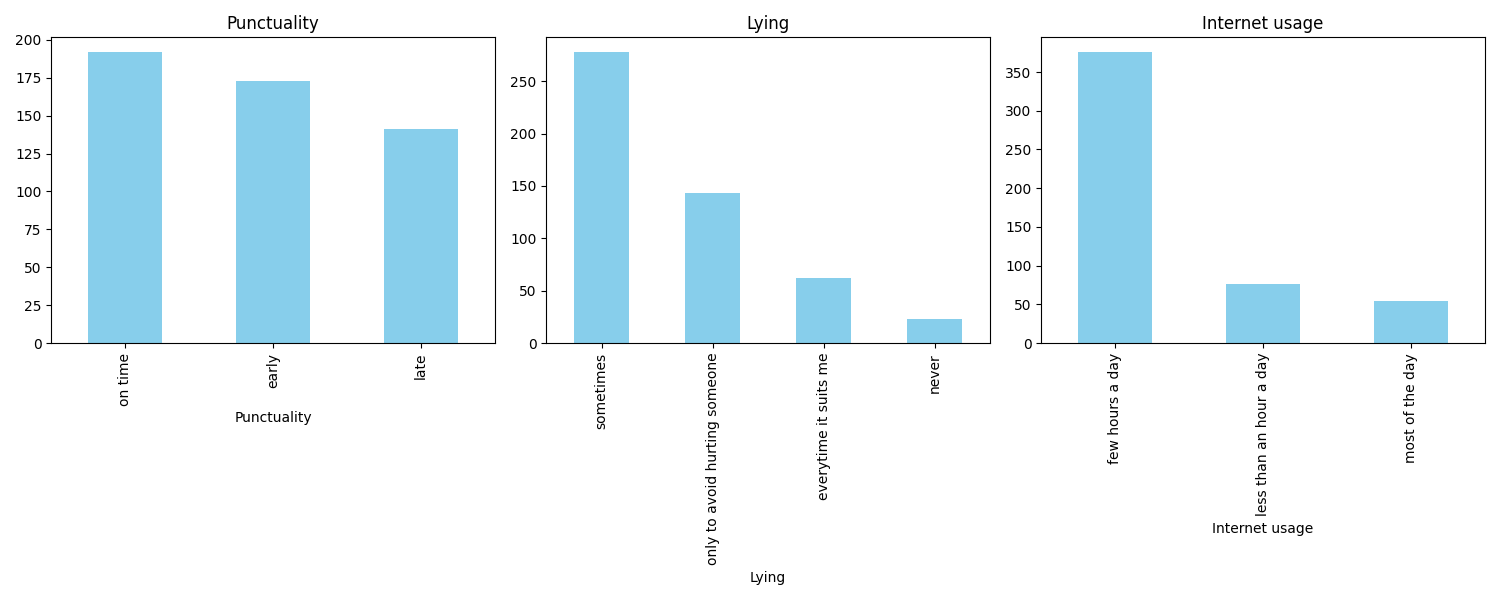

,Finances,Entertainment spending,Spending on looks,Healthy eating,History,Psychology,Politics,Mathematics,Physics,Internet,...,Questionnaires or polls,Internet usage,Flying,Storm,Darkness,Heights,Rats,Ageing,Dangerous dogs,Fear of public speaking
109,4,3,3,3,3,4,3,4,4,5,...,3,3,1,2,2,3,2,2,4,3
552,1,5,5,4,5,1,1,1,1,5,...,1,3,5,3,2,4,2,3,4,4
320,2,2,4,3,1,4,2,3,1,5,...,2,3,2,1,2,4,3,1,3,4
631,3,4,4,3,4,1,4,2,1,4,...,3,3,1,2,2,1,5,3,4,2
498,3,2,2,4,5,4,5,3,2,5,...,3,3,3,2,2,2,4,2,2,2


,Finances,Entertainment spending,Spending on looks,Healthy eating,History,Psychology,Politics,Mathematics,Physics,Internet,...,Questionnaires or polls,Internet usage,Flying,Storm,Darkness,Heights,Rats,Ageing,Dangerous dogs,Fear of public speaking
109,0.847467,-0.158814,-0.076569,0.014622,-0.182252,0.690487,0.265917,1.200166,1.527037,0.903271,...,0.281677,0.086095,-0.818856,0.053357,-0.192103,0.312964,-0.268647,-0.391341,0.736571,0.159072
552,-1.725444,1.532971,1.572101,1.071617,1.421567,-1.708048,-1.280681,-1.054602,-0.890108,0.903271,...,-1.606117,0.086095,2.556630,0.924279,-0.192103,1.085451,-0.268647,0.355898,0.736571,0.997515
320,-0.867807,-1.004706,0.747766,0.014622,-1.786072,0.690487,-0.507382,0.448577,-0.890108,0.903271,...,-0.662220,0.086095,0.025016,-0.817566,-0.192103,1.085451,0.470132,-1.138580,-0.005869,0.997515
631,-0.010170,0.687079,0.747766,0.014622,0.619658,-1.708048,1.039216,-0.303012,-0.890108,-0.208785,...,0.281677,0.086095,-0.818856,0.053357,-0.192103,-1.232009,1.947688,0.355898,0.736571,-0.679371
498,-0.010170,-1.004706,-0.900904,1.071617,1.421567,0.690487,1.812515,0.448577,-0.084393,0.903271,...,0.281677,0.086095,0.868887,0.053357,-0.192103,-0.459523,1.208910,-0.391341,-0.748309,-0.679371


In [5]:
responses_ft_enc = responses_ft.copy()
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(15,6))
responses_ft['Punctuality'].value_counts().plot.bar(ax=axes[0],color = 'skyblue')
axes[0].set_title('Punctuality')
responses_ft['Lying'].value_counts().plot.bar(ax=axes[1],color = 'skyblue')
axes[1].set_title('Lying')
responses_ft['Internet usage'].value_counts().plot.bar(ax=axes[2],color = 'skyblue')
axes[2].set_title('Internet usage')
plt.tight_layout()
plt.show()

ordinal_encoder = OrdinalEncoder()

cat= [
    ['late', 'on time', 'early'],
    ['never', 'only to avoid hurting someone', 'sometimes', 'everytime it suits me'],
    ['no time at all', 'less than an hour a day', 'few hours a day', 'most of the day']
]

ordinal_encoder = OrdinalEncoder(categories=cat)

col = ['Punctuality', 'Lying', 'Internet usage']
responses_ft_enc[col] = (ordinal_encoder.fit_transform(responses_ft[col])+1).astype(int)

responses_ft_enc = pd.DataFrame(
    responses_ft_enc, 
    columns=responses_ft_enc.columns, 
    index=responses_ft_enc.index
)
display(responses_ft_enc.head())

responses_ft_pp = StandardScaler()
responses_ft_pp = responses_ft_pp.fit_transform(responses_ft_enc.values)
responses_ft_pp = pd.DataFrame(
    responses_ft_pp, 
    columns=responses_ft_enc.columns, 
    index=responses_ft_enc.index
)

display(responses_ft_pp.head())


#### Comment the results obtained after the preprocessing operation (max 100 words):
We noticed that the encoding of the category "Internet usage" is missing the value 1, corresponding with the "No time at all" entry, but as shown in the barplot it is perfectly normal, even considering that is a __Young__-People-Survey. 

After the scaling we can say that the weight of each answer is the same for each category, also the 0 values correspond exactly to the mean value and consequentially the positive values are above the average and the negative ones below. We also notice very high values, possibly indicate extreme cases, such as the 2.55 entry in the Flying-phobia column.

## Exercise 2. Analyzing the Variance and the PCs

In this exercise, you have to do the following operations:
1. compute and visualize the variance of all the features in *responses_ft_enc* and *responses_ft_pp*;
1. compute all the $n$ Principal Components (PCs) for *responses_ft_enc* and *responses_ft_pp*, separately, and visualize the curves of the cumulative explained variances.

For doing this exercise, fill the cells below following the instructions you read.

#### Write the code for computing and visualizing the variance of the features of the two datasets:

,Variance (Encoded),Variance (Standardized)
Finances,1.362235,1.00198
Entertainment spending,1.400325,1.00198
Spending on looks,1.474524,1.00198
Healthy eating,0.896838,1.00198
History,1.558146,1.00198
...,...,...
Heights,1.679102,1.00198
Rats,1.835824,1.00198
Ageing,1.794486,1.00198
Dangerous dogs,1.817759,1.00198


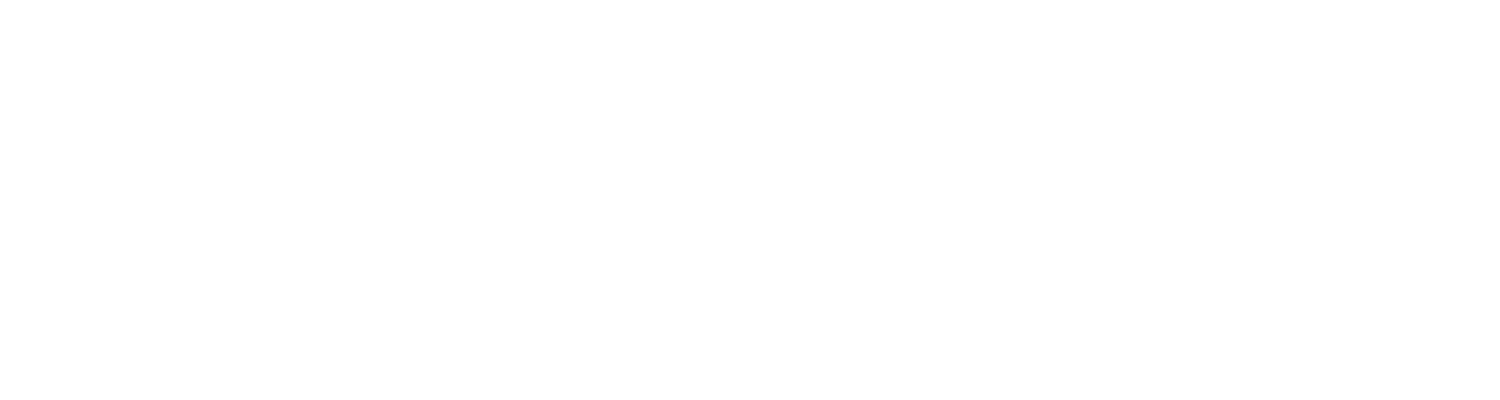

In [6]:
set3 = cm.Set3.colors
type_colors = {
    'Finance': set3[0],
    'Health': set3[1],
    'Interests': set3[2],
    'Movies': set3[3],
    'Music': set3[4],
    'Personality': set3[5],
    'Phobias': set3[6]
}

feature_to_type = {}
for category, feature_list in features_by_type.items():
    for feature in feature_list:
        feature_to_type[feature] = category

colors_type = []
for feature_name in responses_ft_enc.columns:
    category = feature_to_type.get(feature_name)
    color = type_colors[category]
    colors_type.append(color)

type_legendelements = [
    Patch(facecolor=color, edgecolor='black', label=category) 
    for category, color in type_colors.items()
]
n = len(features)
X_enc = responses_ft_enc.values
vars_enc = responses_ft_enc.var(axis=0)

X_pp = responses_ft_pp.values
vars_pp = responses_ft_pp.var(axis=0)

vars_enc = pd.DataFrame(
    vars_enc, 
    columns=['Variance'], 
    index=vars_enc.index
)

vars_pp = pd.DataFrame(
    vars_pp, 
    columns=['Variance'], 
    index=vars_pp.index
)
comparison_df = pd.concat([vars_enc, vars_pp], axis=1)

comparison_df.columns = ['Variance (Encoded)', 'Variance (Standardized)']

display(comparison_df)

plt.figure(figsize=(15,4))
plt.bar(np.arange(n), vars_enc['Variance'],color=colors_type)
plt.title("FEATURES' VARIANCE (ENCODED)")
plt.xlabel('Features')
plt.ylabel('Variance')
plt.legend(
    handles=type_legendelements, 
    loc='upper left', 
    bbox_to_anchor=(1.02, 1), 
    borderaxespad=0
)
plt.grid(True,linestyle='--',linewidth=0.5,alpha=0.7)
plt.tight_layout()
plt.show()

# We decided not to visualize the features' variance plot for the preprocessed one, because it would be not significative, 
# considering that the data is standardized and the variances are all the same as we can see from the table

#### Comment the results obtained for the variances (max 150 words):
In general we can see that there is no predominant feature in the *responses_ft_enc*. Also, considering that we have a clean dataset, we can expect to not find any "raw" data with a very high variance and actually that is showed in the barplot above, so without the standardization, due to the nature of the dataset we have variance differences, nevertheless there is no dominant one.

After the standardization obtained after the preprocessing with the Standard Scaler we can see that the variances of *responses_ft_pp* features are all the same, which is reasonable considering that we want to prevent variables with larger variance discussed before to dominate in the PCA.

#### Write the code for computing all the $n$ PCs of the two datasets, separately, and for visualizing the curves of cumulative explained variances:

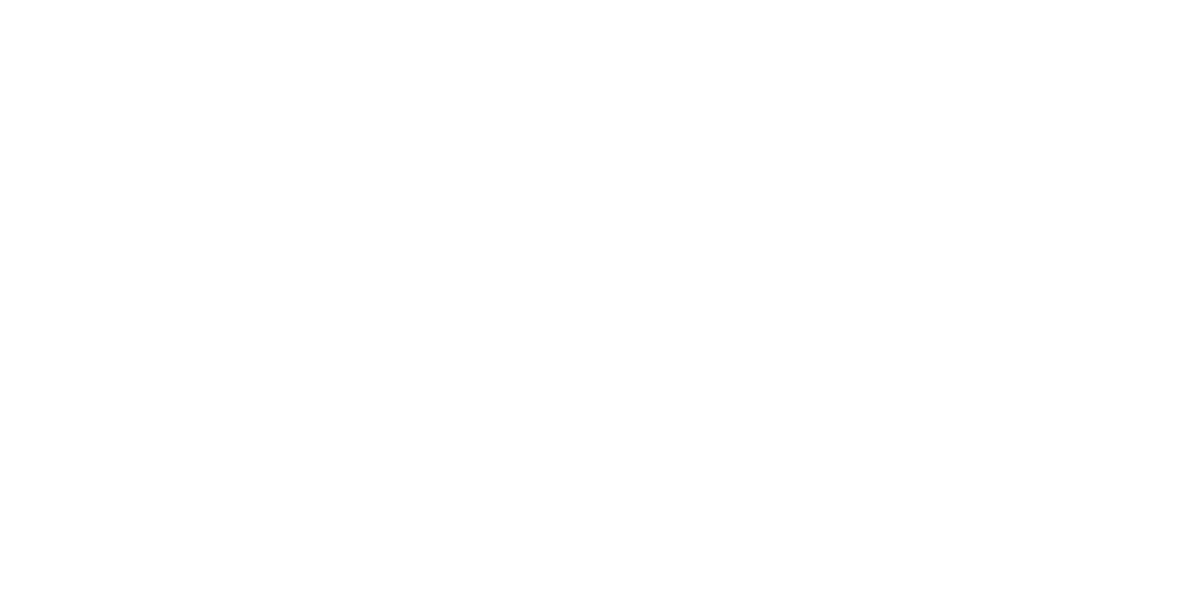

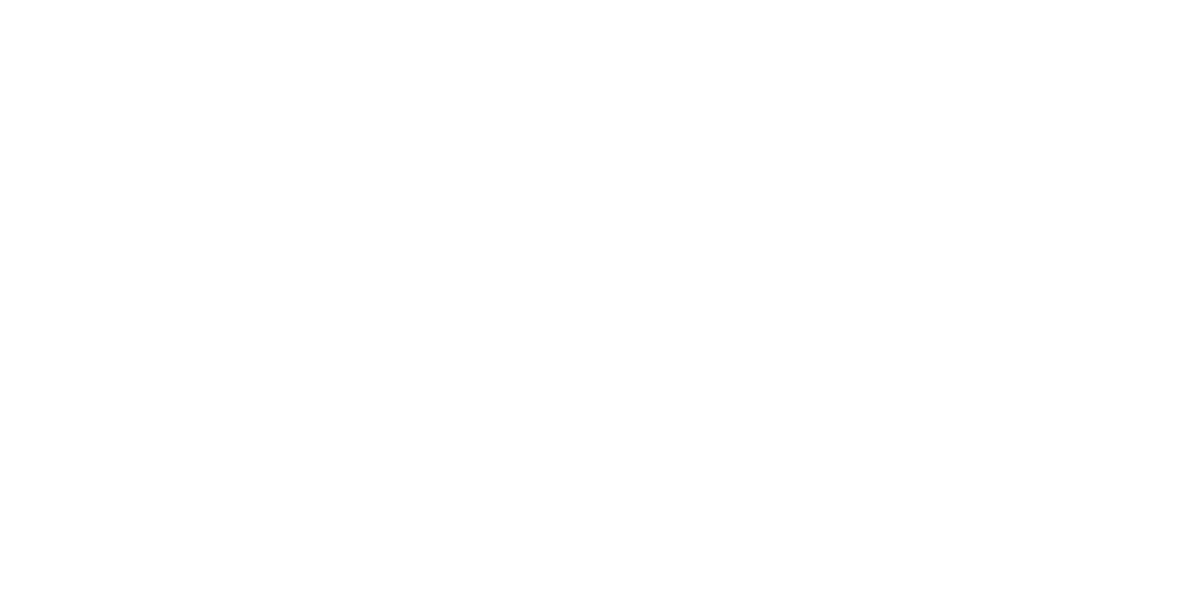

In [7]:
pca_full_enc = PCA()
pca_full_enc.fit(responses_ft_enc)
plt.figure(figsize=(12,6))
plt.bar(np.arange(pca_full_enc.n_features_in_),pca_full_enc.explained_variance_ratio_,bottom=np.insert(np.cumsum(pca_full_enc.explained_variance_ratio_),0,0)[:-1])
plt.bar(np.arange(pca_full_enc.n_features_in_),np.insert(np.cumsum(pca_full_enc.explained_variance_ratio_),0,0)[:-1],color='b',alpha=0.15)
plt.plot(np.cumsum(pca_full_enc.explained_variance_ratio_),'r')
plt.axhline(y=0.33, color='g', linestyle='--')  # Line to observe the 33% of the total variance required later
plt.title('PCs (Encoded)')
plt.xticks(np.arange(pca_full_enc.n_features_in_)[::4], rotation=45,labels=[f'PC{i}' for i in range(1,pca_full_enc.n_features_in_+1)][::4]) 
plt.xlabel('Principal Components')
plt.ylabel('Cumulative explained variance(%)')
plt.grid(True,linestyle='--',linewidth=0.5,alpha=0.7)
plt.tight_layout()
plt.show()

pca_full_pp = PCA()
pca_full_pp.fit(responses_ft_pp)
plt.figure(figsize=(12,6))
plt.bar(np.arange(pca_full_pp.n_features_in_),pca_full_pp.explained_variance_ratio_,bottom=np.insert(np.cumsum(pca_full_pp.explained_variance_ratio_),0,0)[:-1])
plt.bar(np.arange(pca_full_pp.n_features_in_),np.insert(np.cumsum(pca_full_pp.explained_variance_ratio_),0,0)[:-1],color='b',alpha=0.15)
plt.plot(np.cumsum(pca_full_pp.explained_variance_ratio_),'r')
plt.axhline(y=0.33, color='g', linestyle='--')
plt.title('PCs (Standardized)')
plt.xticks(np.arange(pca_full_pp.n_features_in_)[::4], rotation=45,labels=[f'PC{i}' for i in range(1,pca_full_pp.n_features_in_+1)][::4])
plt.xlabel('Principal Components')
plt.ylabel('Cumulative explained variance(%)')
plt.grid(True,linestyle='--',linewidth=0.5,alpha=0.7)
plt.tight_layout()
plt.show()

#### Comment the results obtained for the cumulative explained variances, knowing the values in the datasets and the features' variances (max 150 words):

In general we can observe that, considering that the dataset has numerous features which are not so much related to each other, the cumulative explained variance takes a very large number of principal components to reach a decent value that preserves the loss of information in both of enocoded and standardized data. Since that the main purpose is to reduce the number of principal component, we are amenable to lose some information for the sake of the dimension reduction.

Ultimately we can see that for the encoded data the cumulative explained variance takes less components to reach each percentage threshold than the preprocessed one, because before the standardization we have features (the once categorical ones) which have a larger variance due a different scale (1-3 or 1-4) and they may condition the cumulative one. 

## Exercise 3. Dimensionality Reduction and PC Interpretation

In this exercise, you have to do the following operations:
1. For the dataset *responses_ft_pp*, compute a new PCA for performing a dimensionality reduction with respect to $m$ dimensions. The value of $m$ must be $$m = \min\{m', 5\}\,,$$ where $m'$ is the value required for obtaining $33\%$ of the total variance.
1. Visualize as a barplot the explained variance (as percentage) for each PC, and report the preserved explained variance (as percentage) by the $m$ PCs.
1. Visualize all the PCs as barplots and give an interpretation and a name to them, **motivating your choices**.
1. Transform the *responses_ft_pp* data into their $m$-dimensional representation via PCA. Store the transformed data in the variable *responses_ft_pca*;
1. Visualize the the score graph. If $m>3$, plot the score graph with respect to the first 3 PCs. All the **plots must show the names of the PCs (given at the previous step) on the axes** for better understanding the results.

#### Write the code for computing the new PCA, for visualizing the $m$ PCs as barplots:

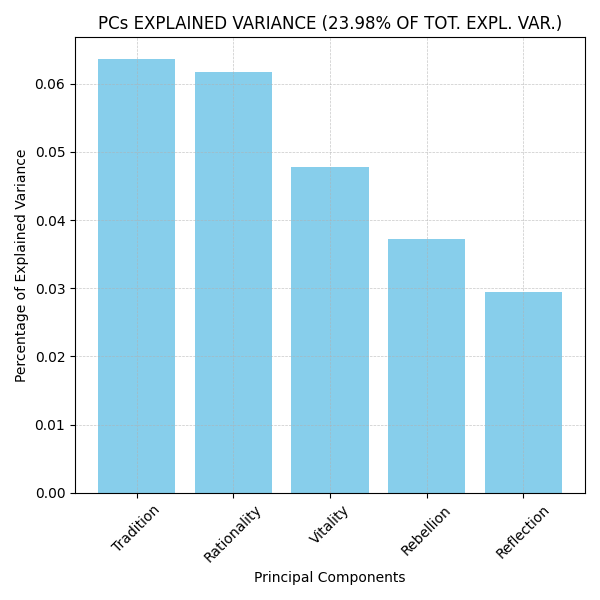

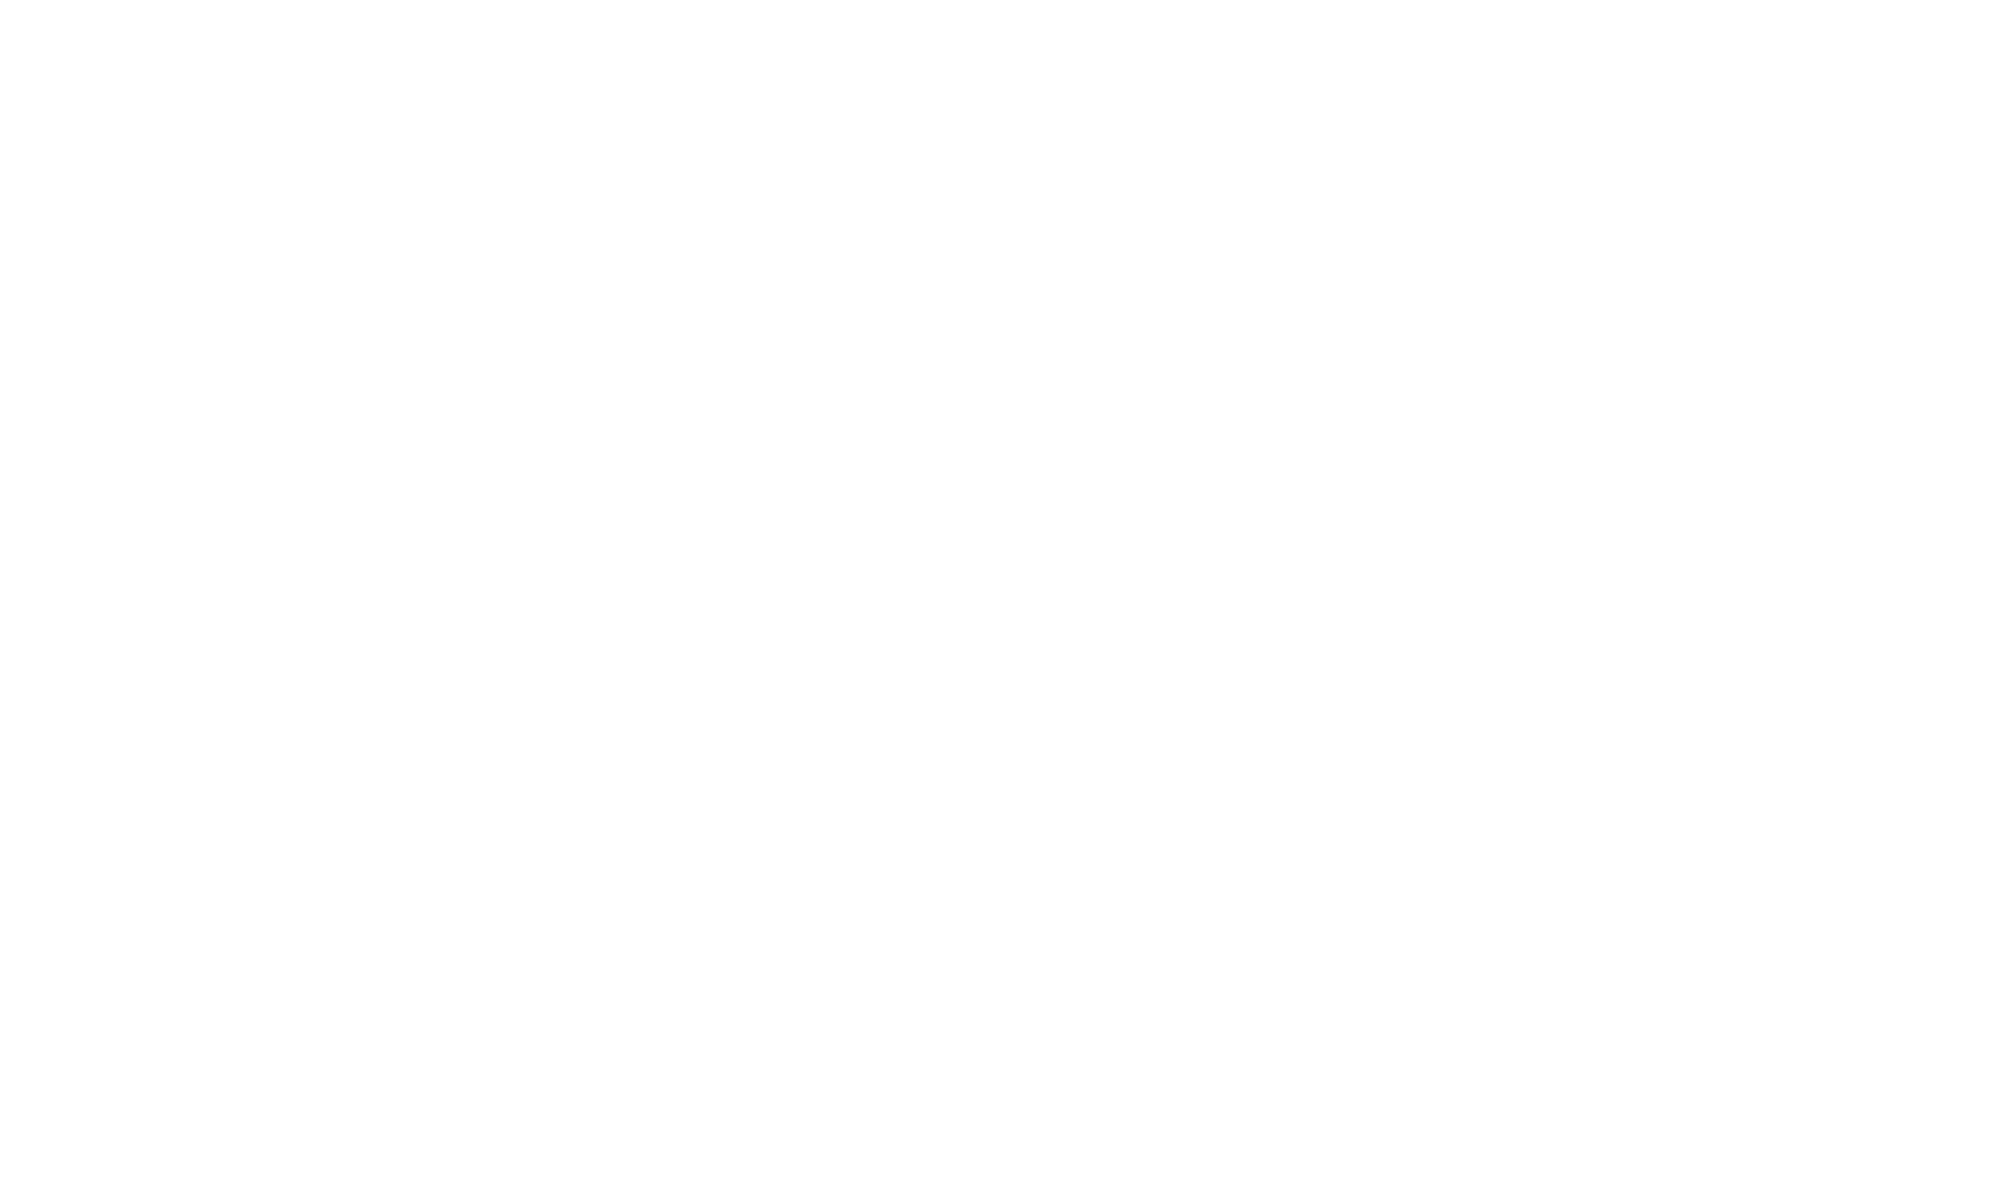


** PC1 **
HIGH-VALUED POSITIVE COMPONENTS: ['Classical music', 'Folk', 'Opera', 'Latino', 'Writing notes', 'Dancing', 'Swing, Jazz', 'Religion', 'Reading', 'Countryside, outdoors', 'Biology', 'Musical instruments', 'Fantasy/Fairy tales', 'Gardening', 'Healthy eating', 'Medicine', 'Romantic', 'Prioritising workload', 'Psychology', 'God', "Parents' advice", 'Country', 'Rock n roll', 'Children', 'Writing', 'Finances', 'Questionnaires or polls', 'Reliability', 'Animated', 'Empathy', 'Final judgement', 'Decision making', 'Alternative']

HIGH-VALUED NEGATIVE COMPONENTS: ['Cheating in school', 'Criminal damage', 'Internet usage']
*



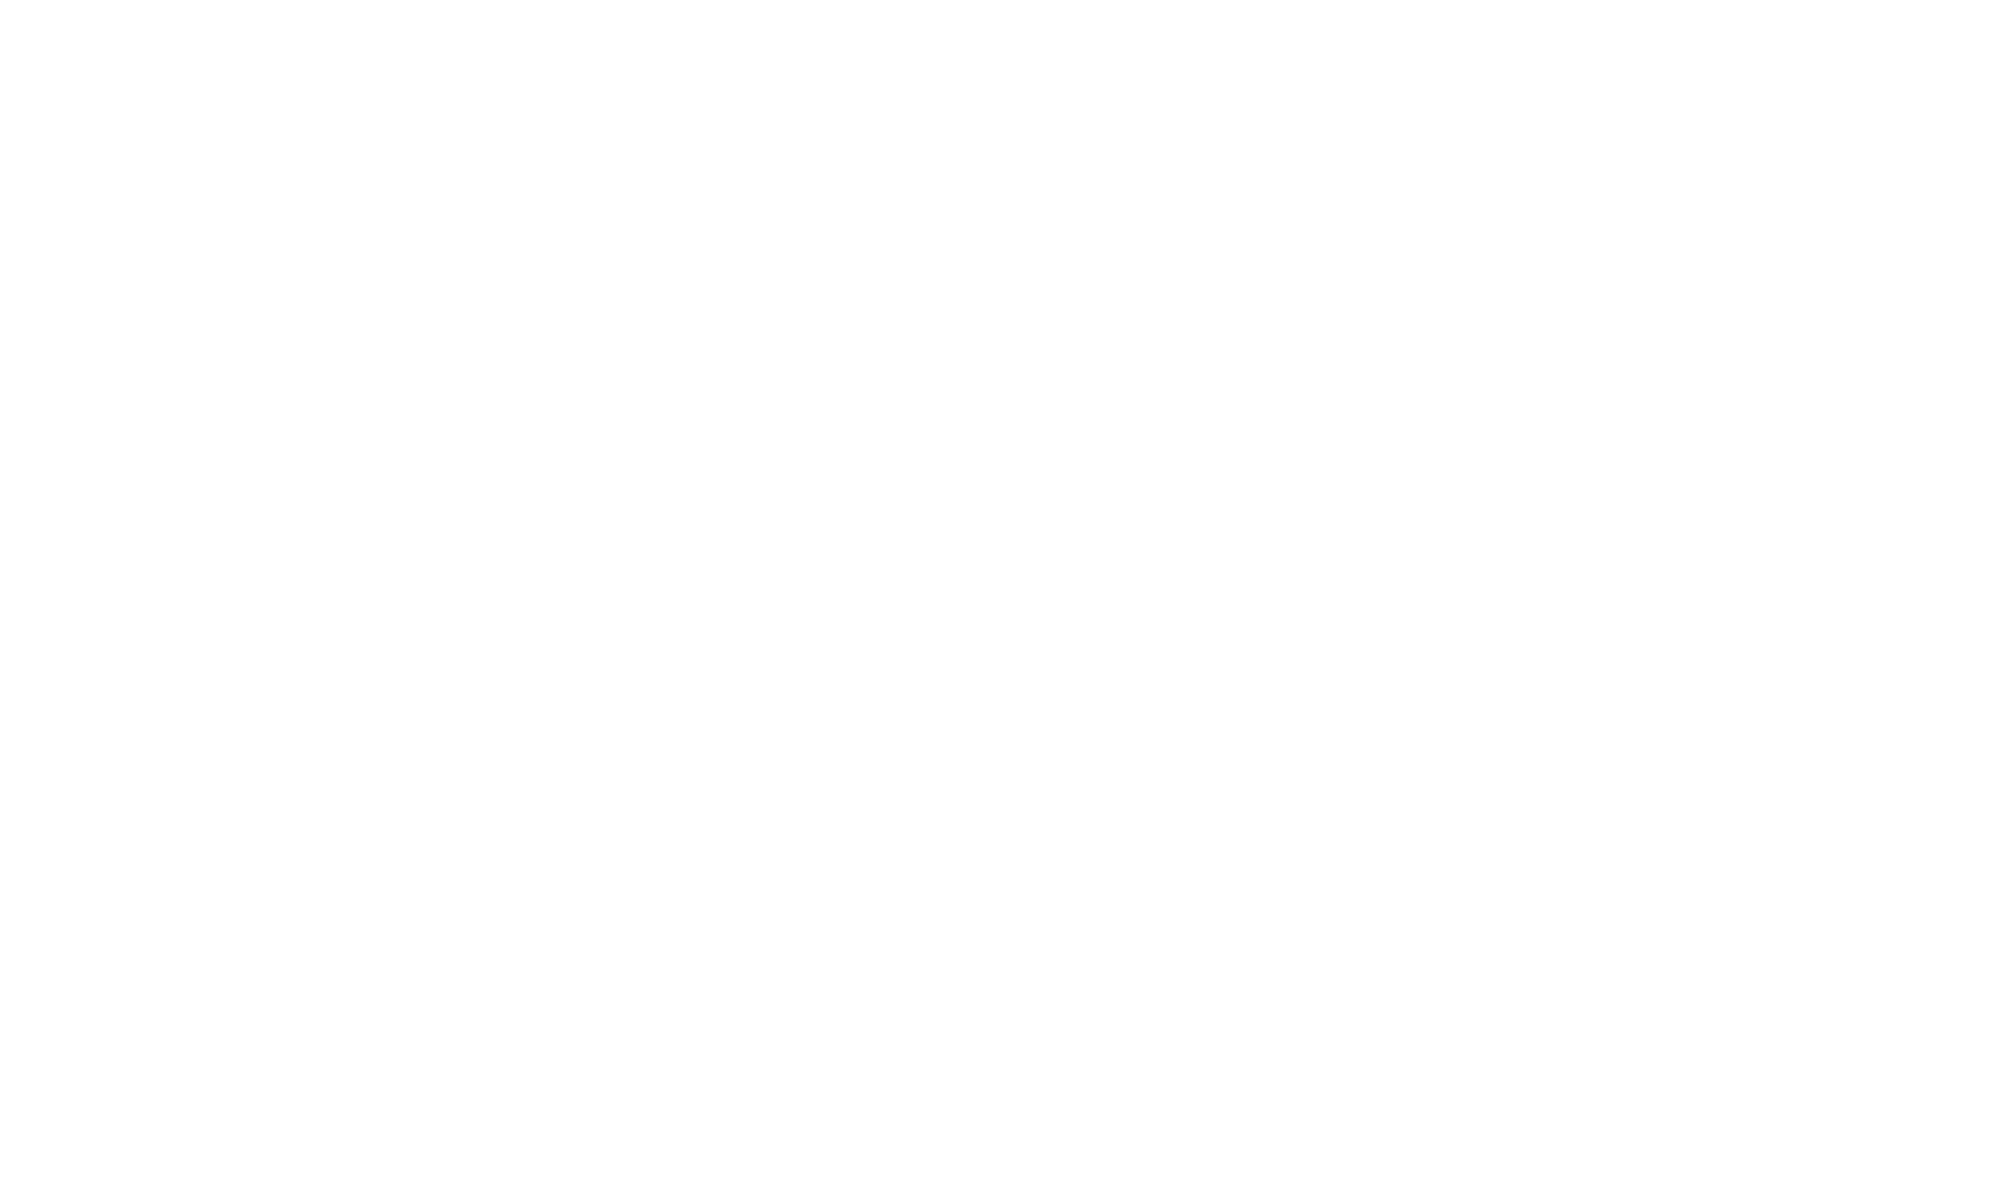


** PC2 **
HIGH-VALUED POSITIVE COMPONENTS: ['Science and technology', 'War', 'Sci-fi', 'Physics', 'Western', 'PC', 'Interests or hobbies', 'Politics', 'Active sport', 'Mathematics', 'Entertainment spending', 'Socializing', 'History', 'Small - big dogs', 'Number of friends', 'Energy levels', 'Rock n roll', 'Swing, Jazz', 'Reggae, Ska', 'Assertiveness', 'Funniness', 'Horror', 'Thriller', 'Waiting']

HIGH-VALUED NEGATIVE COMPONENTS: ['Public speaking', 'Storm', 'Darkness', 'Dangerous dogs', 'Fear of public speaking', 'Flying', 'Rats', 'Romantic', 'Mood swings', 'Decision making', 'Heights', 'Getting angry', 'Health']
*



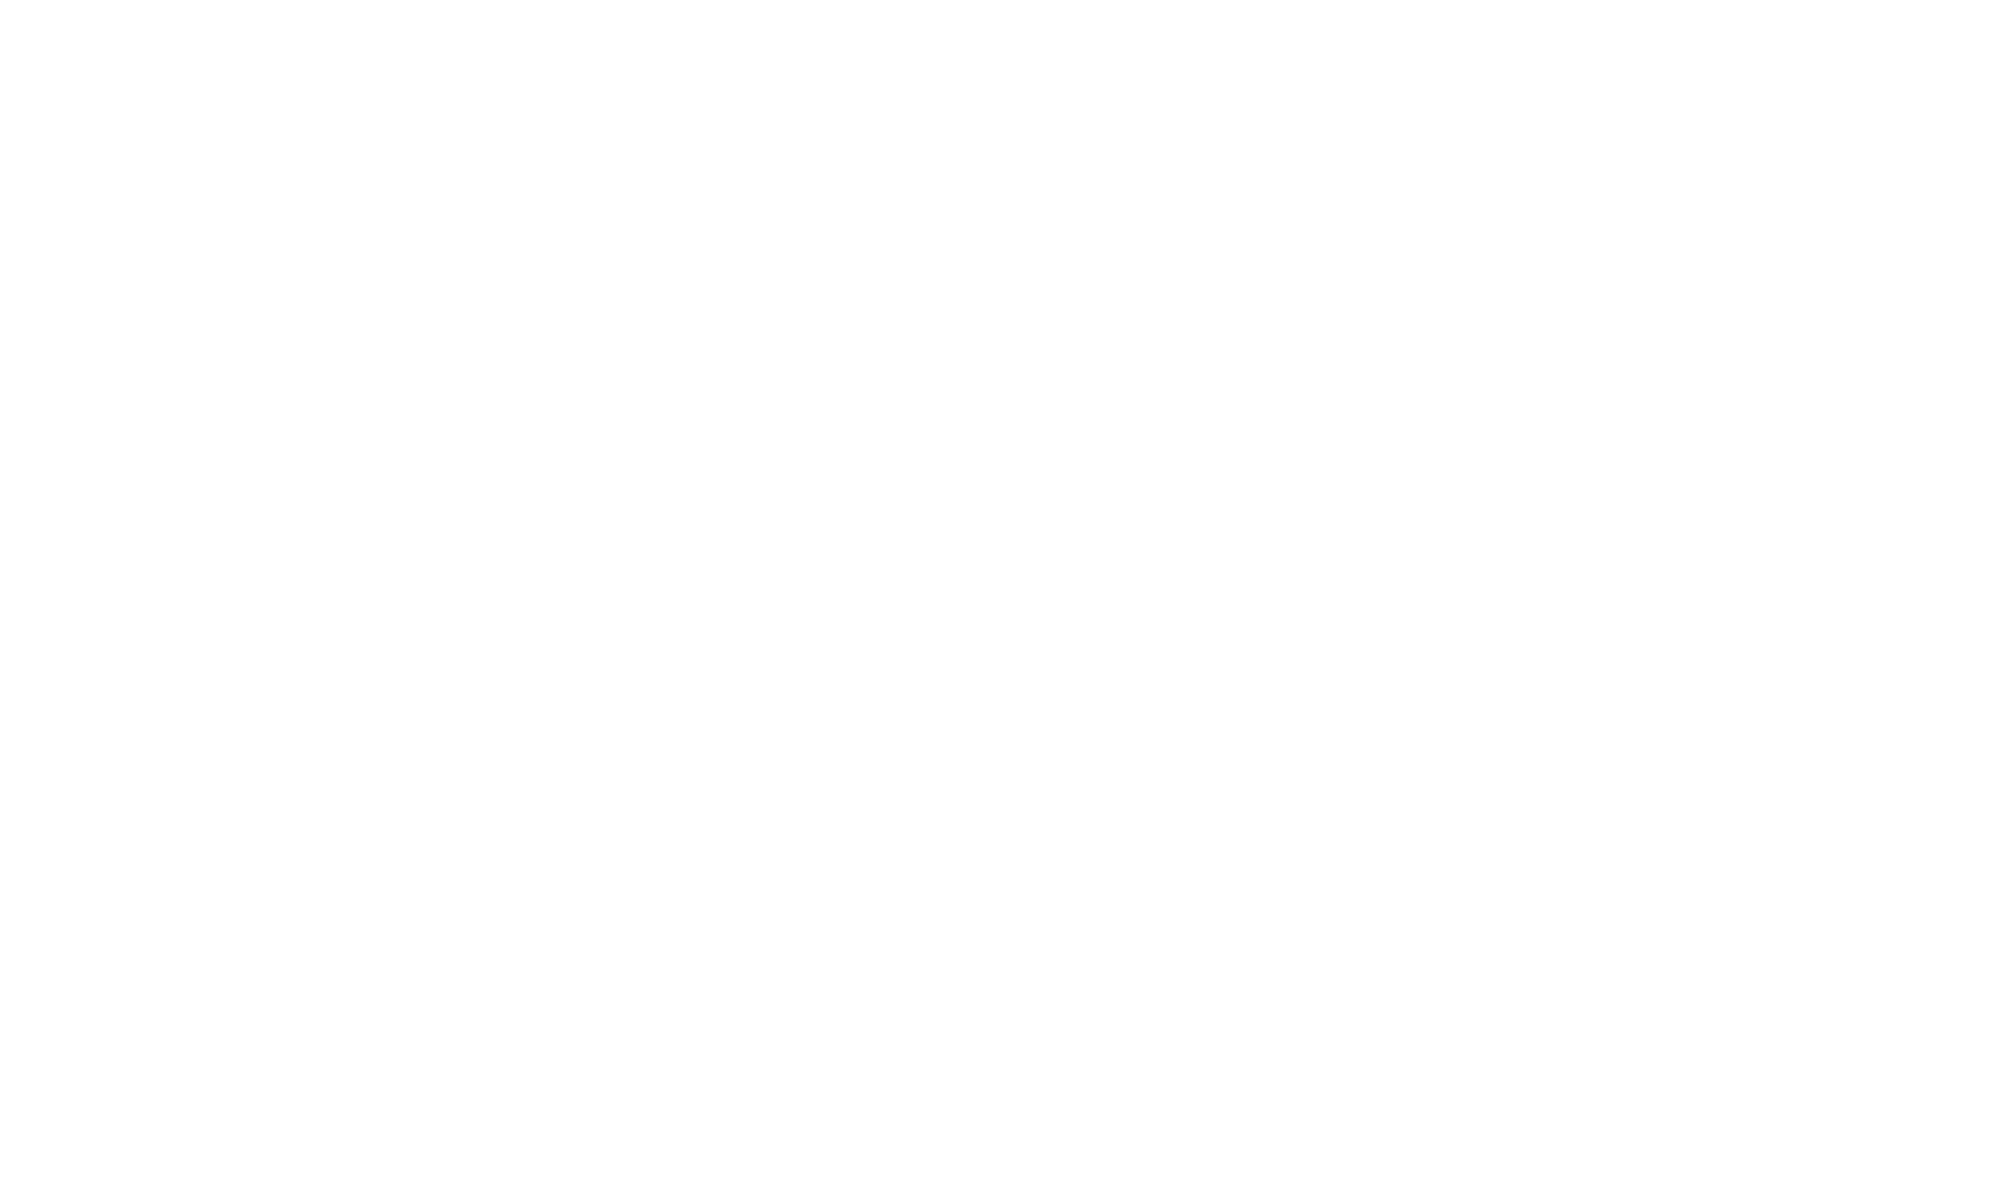


** PC3 **
HIGH-VALUED POSITIVE COMPONENTS: ['Energy levels', 'Number of friends', 'Spending on looks', 'Happiness in life', 'Socializing', 'Fun with friends', 'Entertainment spending', 'Interests or hobbies', 'Dancing', 'Cheating in school', 'Active sport', 'Romantic', 'Children', 'Latino']

HIGH-VALUED NEGATIVE COMPONENTS: ['Classical music', 'Self-criticism', 'Sci-fi', 'Physics', 'Fake', 'Fear of public speaking', 'Thinking ahead', 'Country', 'Western', 'Internet usage', 'Changing the past', 'Mathematics', 'PC', 'Opera', 'Finances', 'Mood swings', 'Writing']
*



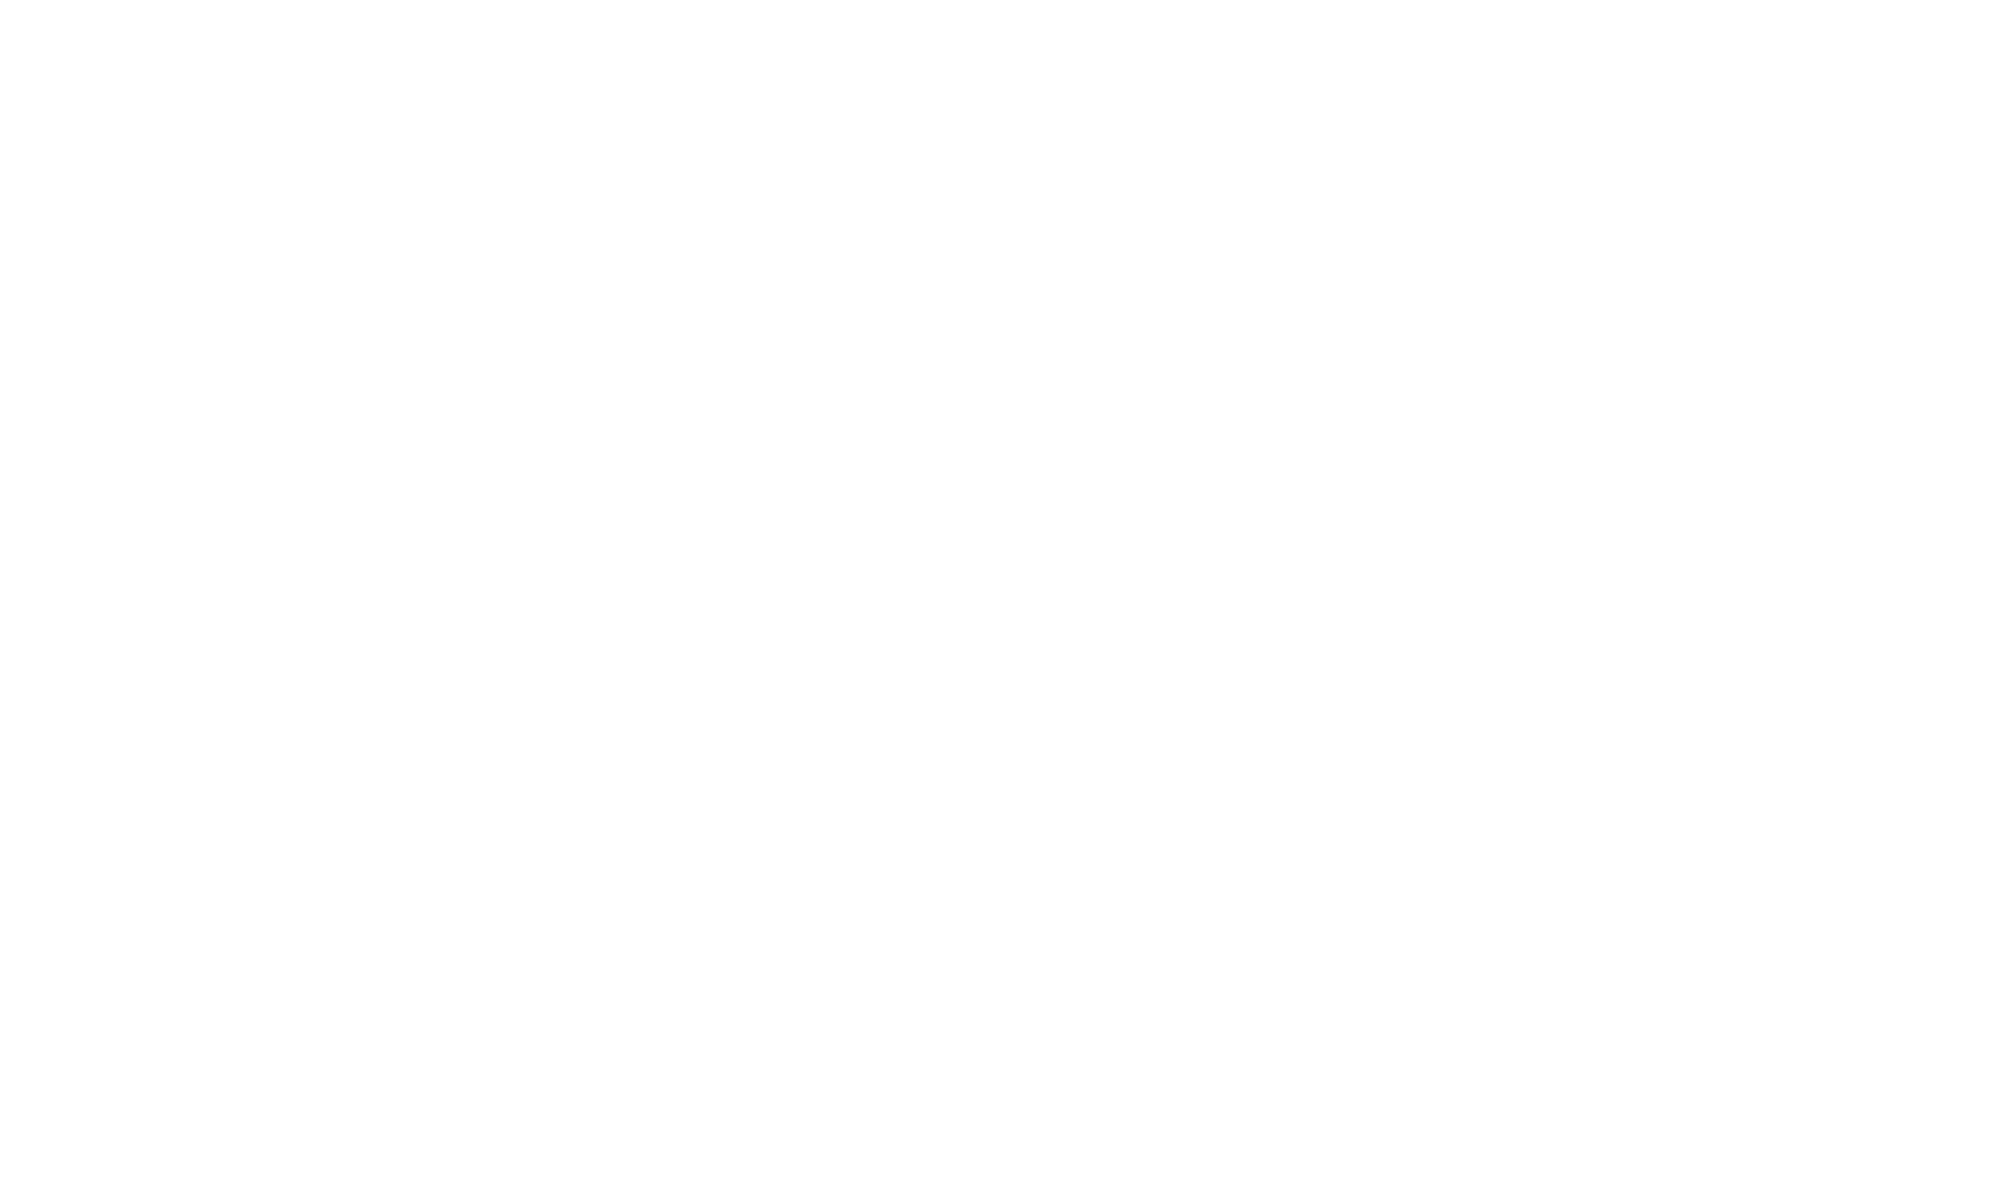


** PC4 **
HIGH-VALUED POSITIVE COMPONENTS: ['Getting up', 'Changing the past', 'Ageing', 'Alternative', 'Cheating in school', 'Criminal damage', 'Getting angry', 'Swing, Jazz', 'Darkness', 'Rock n roll', 'Spending on looks', 'Animated', 'Entertainment spending', 'Movies', 'Fantasy/Fairy tales', 'Mood swings', 'Internet usage', 'Horror', 'Hypochondria', 'Funniness', 'Lying', 'Fun with friends', 'Loss of interest', 'Writing', 'Reading', 'Thriller', 'Classical music', 'Fake', 'Rats', 'Psychology', 'Musical instruments']

HIGH-VALUED NEGATIVE COMPONENTS: ['Prioritising workload', 'Finances', 'Happiness in life', 'Punctuality', 'Mathematics', 'Physics', 'Thinking ahead', 'Reliability', 'Waiting']
*



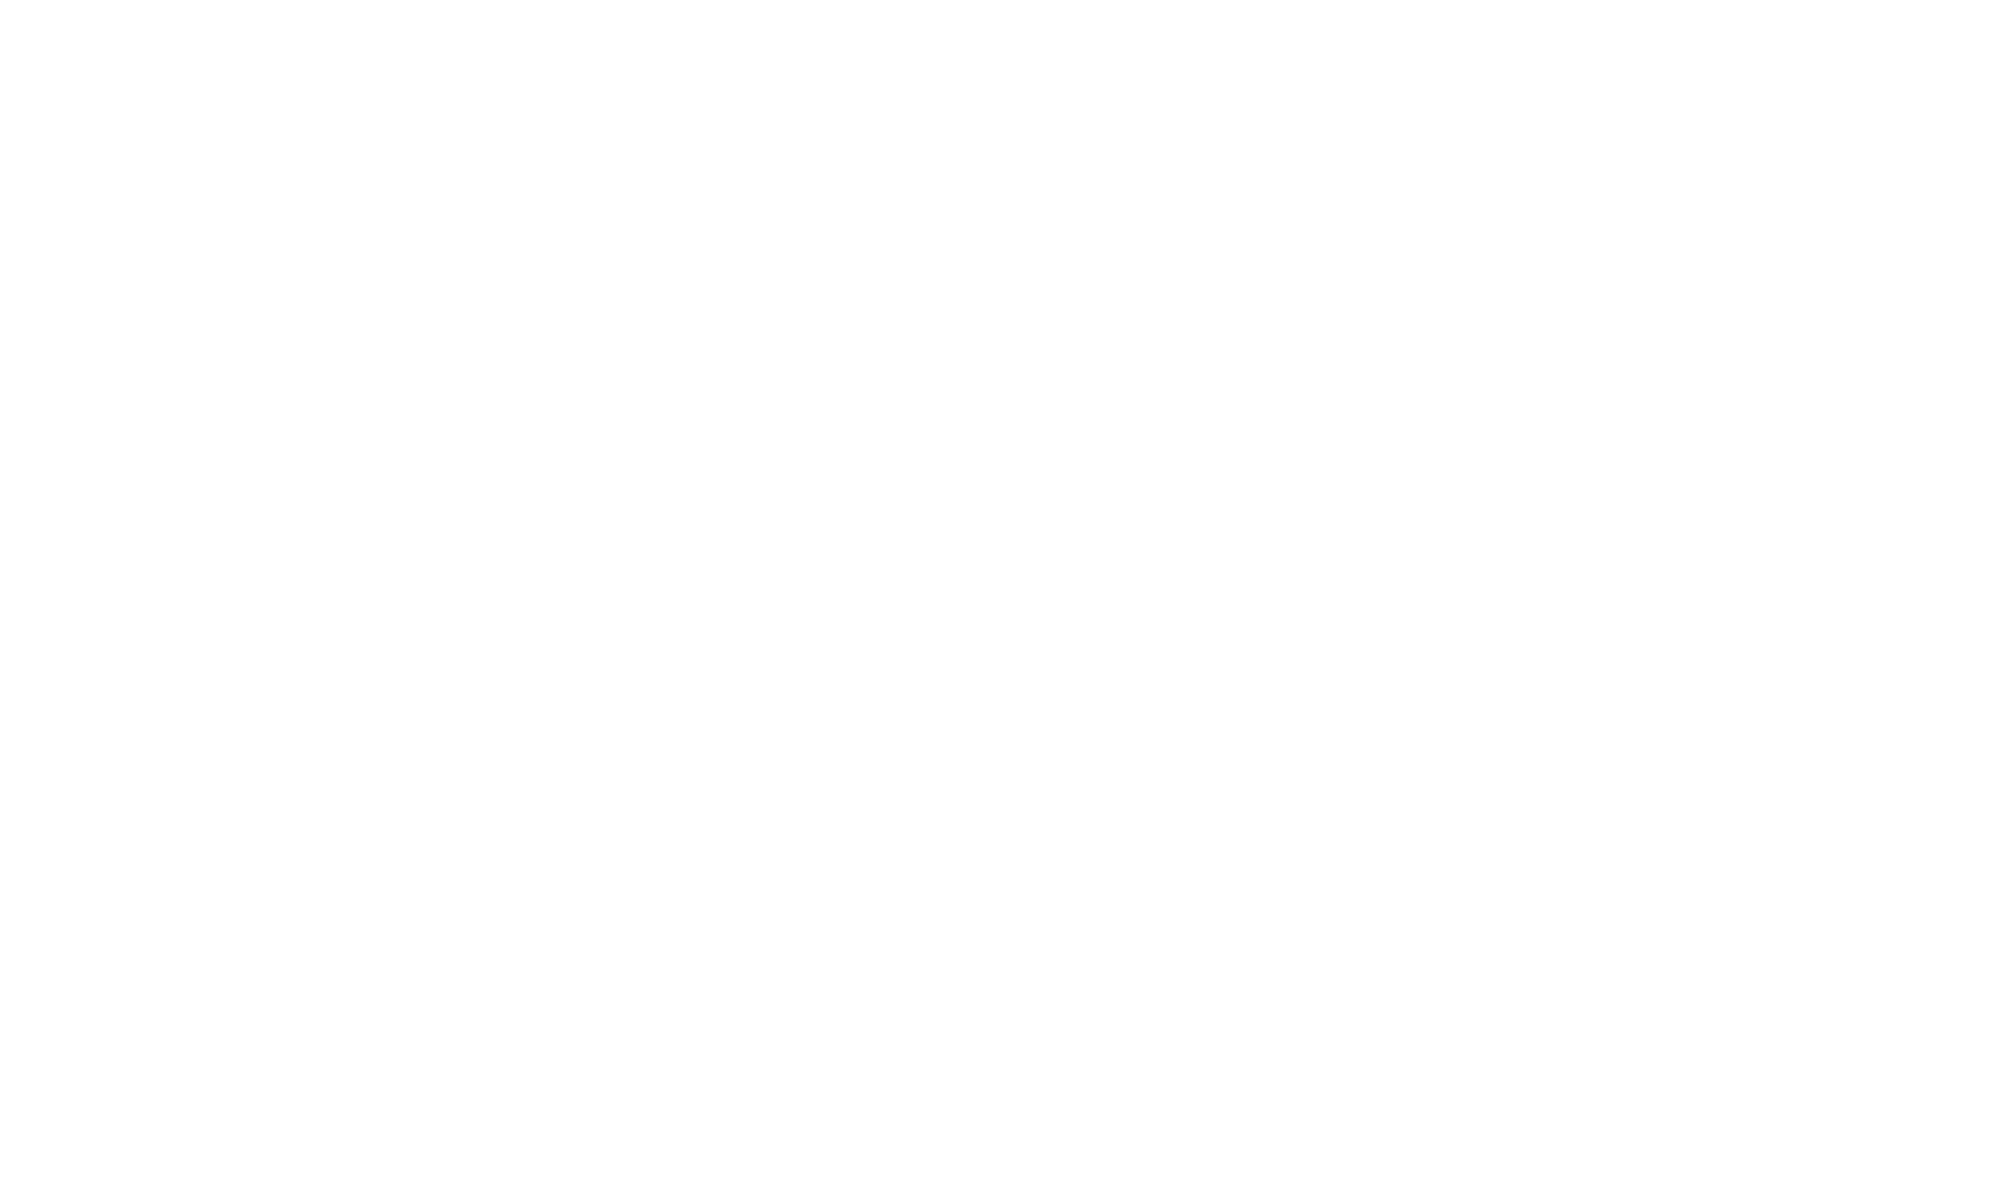


** PC5 **
HIGH-VALUED POSITIVE COMPONENTS: ['Internet', 'PC', 'Health', 'Economy Management', 'Science and technology', 'Rats', 'Mathematics', 'Thinking ahead', 'Healthy eating', 'Dangerous dogs', 'Techno, Trance', 'Spending on looks', 'Decision making', 'Physics', "Parents' advice", 'Funniness', 'Thriller', 'Passive sport', 'Reliability', 'Prioritising workload', 'Punctuality', 'Public speaking', 'Final judgement', 'Internet usage', 'Storm']

HIGH-VALUED NEGATIVE COMPONENTS: ['Reading', 'Alternative', 'Small - big dogs']
*



In [8]:
#The 33% of the total variance is for m'=9 so we choose the minimum between m' and 5 and that would be the latter
m = 5
pca = PCA(n_components=m)
pca.fit(responses_ft_pp)

round_expl_var_ratio = np.round(pca.explained_variance_ratio_.sum() * 100, decimals=2)
eps = np.sqrt(1 / pca.n_features_in_)
pc_names = [
    'Tradition',
    'Rationality',
    'Vitality',          # We assigned these names after a first output without them
    'Rebellion',
    'Reflection'
]
plt.figure(figsize=(6, 6))
plt.bar(range(1, m + 1), pca.explained_variance_ratio_,color = 'skyblue')
plt.title(f"PCs EXPLAINED VARIANCE ({round_expl_var_ratio}% OF TOT. EXPL. VAR.)")
plt.xticks(
    ticks=np.arange(1, m + 1),
    labels=[f'{pc_names[i-1]}' for i in range(1, m + 1)],
    rotation=45
)
plt.xlabel('Principal Components')
plt.ylabel('Percentage of Explained Variance')
plt.grid(True, linestyle='--', linewidth=0.5, alpha=0.7)
plt.tight_layout()
plt.show()
for i in range(m):
    plt.figure(figsize=(20, 12))
    plt.bar(
        np.arange(pca.n_features_in_),
        pca.components_[i, :],
        color=colors_type
    )

    plt.plot([-0.5, pca.n_features_in_ - 0.5], [eps, eps], 'red')   #Threshold for determine which are high-valued components (positive/negative)
    plt.plot([-0.5, pca.n_features_in_ - 0.5], [-eps, -eps], 'red')

    plt.xticks(
        ticks=np.arange(pca.n_features_in_),
        labels=features,
        rotation=90
    )

    plt.title(f'{pc_names[i]}- PC{i + 1}')
    plt.legend(handles=type_legendelements)
    plt.grid(True, linestyle='--', linewidth=0.5, alpha=0.7)
    plt.tight_layout()
    plt.show()

    ind_great_pos = np.argwhere(pca.components_[i, :] >= eps).flatten()
    ind_great_neg = np.argwhere(pca.components_[i, :] <= -eps).flatten()

    vals_pos = pca.components_[i, ind_great_pos]
    vals_neg = pca.components_[i, ind_great_neg]
    
    sorted_ind_pos = ind_great_pos[np.argsort(vals_pos)[::-1]]
    sorted_ind_neg = ind_great_neg[np.argsort(vals_neg)]
    
    great_pos_PCi = [features[idx] for idx in sorted_ind_pos]
    great_neg_PCi = [features[idx] for idx in sorted_ind_neg]
    print('')
    print('**', f'PC{i+1}', '**')
    print(f'HIGH-VALUED POSITIVE COMPONENTS: {great_pos_PCi}')
    print('')
    print(f'HIGH-VALUED NEGATIVE COMPONENTS: {great_neg_PCi}')
    print('*')
    print('')

#### For each PC, write the name you assigned to it and a brief interpretation that motivate the choice (max 100 words per PC):

PC1 __Tradition__: We noticed the presence of several interests concerning the traditional culture, namely the passion for the classical, folk, opera, latino and swing/jazz music, alongside the ones towards dancing, religion, poetry reading and outdoors activity. These people are stuck to traditional values and they prefer non-technological activities and considering all of that we decided that "Tradition" could be a suitable label.


PC2 __Rationality__: Considering the fact that there is a general preference for the world of science and technology, physics and computers and these people also lean towards social and political engagements, these features describe a mindset guided by logical and analytical thinking and that's supported by the fact that we have negative values for most of the fears and a complete disinterest for emotions of any sort. So we decided to call this component "Rationality".


PC3 __Vitality__: This component describes outgoing people and indeed we have high values in all the activities related to social intaractions or a more general life enjoying with a more hedonistic side and an active partecipation in physical exercises. If we take a look at the negative components we can see there is an aversion for logical or even deep arguments in addition to a repulsion for a self-loathing view of life: these are the people which describe the word "Vitality".


PC4 __Rebellion__: We can see a general will of breaking the rules and resisting the society-imposed structures but even a very low energy towards positive behaviours and life. They are also very moody and this can be confirmed by the fact that they have lots of fears but nevertheless they appreciate horror and thriller films. On the negative values we can see that they are not interested in their future or in more pragmatic things, thus the name "Rebellion". 


PC5 __Reflection__: For this component we can see a self-aware attitude and introspection thinking focusing on consequences of choices over time. These individuals have high values also for a moderate large number of fears which indicates that they really care about anything that could happen to them. On the other end we can see a preference for smaller dogs, which are more manageable and a disliking for the poetry and the alternative music. These are the "reflective" people.

#### Write the code for visualizing the score graph (with PC names on the axis):

,Tradition,Rationality,Vitality,Rebellion,Reflection
0,1.662536,0.968682,-2.893002,-2.090071,2.384219
1,-2.690159,-2.755508,3.988751,-1.448614,2.407040
2,-6.079842,-1.310241,-1.407082,-0.093927,0.993024
3,0.713508,0.835476,0.055337,3.463768,-0.474515
4,1.435503,0.708104,2.192358,-2.792686,-0.682830
...,...,...,...,...,...
501,3.373170,-1.906421,2.713007,-1.782526,-1.000724
502,-1.490554,-1.969784,-0.267861,2.072885,-1.060095
503,-2.056669,-1.277707,1.259461,3.099886,-0.413563
504,1.328724,-2.391077,-1.876392,-0.417060,-1.536795


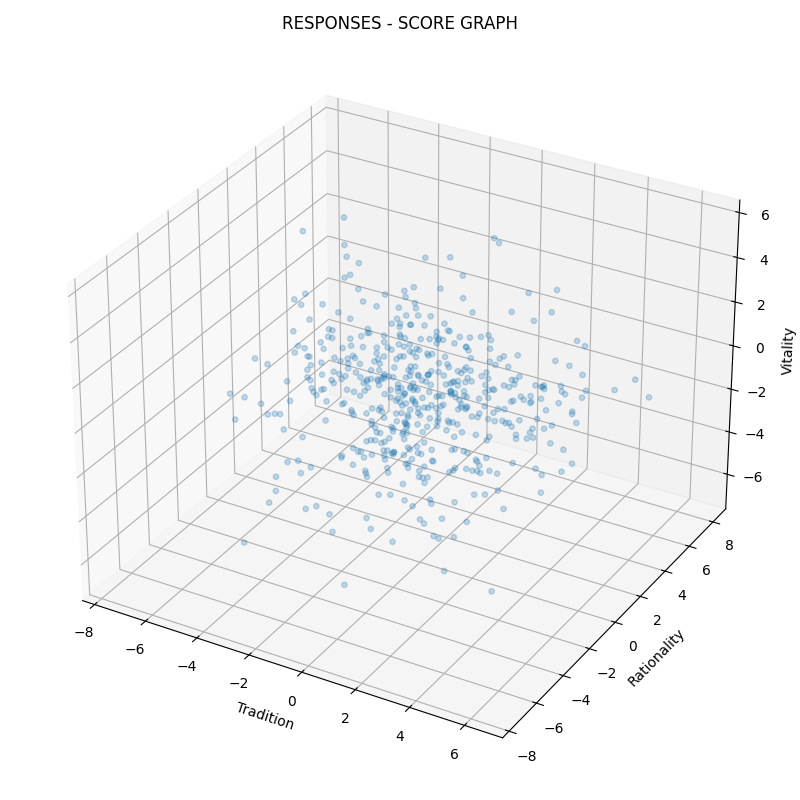

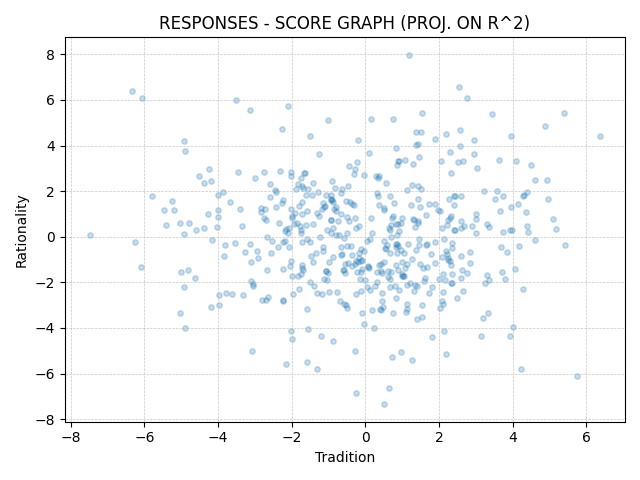

In [9]:
responses_ft_pca = pca.transform(responses_ft_pp)
responses_ft_pca_df = pd.DataFrame(responses_ft_pca, columns=pc_names)
display(responses_ft_pca_df)

sg_3d = plt.figure(figsize=(8, 8))
ax_3d = sg_3d.add_subplot(111, projection='3d')

ax_3d.scatter(responses_ft_pca[:, 0], responses_ft_pca[:, 1], responses_ft_pca[:, 2], s=15, alpha=0.25)
ax_3d.set_title('RESPONSES - SCORE GRAPH')

ax_3d.set_xlabel(pc_names[0])
ax_3d.set_ylabel(pc_names[1])
ax_3d.set_zlabel(pc_names[2])
ax_3d.grid(True, linestyle='--', linewidth=0.5, alpha=0.7)
plt.tight_layout()
plt.show()
plt.figure()

plt.scatter(responses_ft_pca[:, 0], responses_ft_pca[:, 1], s=15, alpha=0.25)
plt.title('RESPONSES - SCORE GRAPH (PROJ. ON R^2)')

plt.xlabel(pc_names[0])
plt.ylabel(pc_names[1])

plt.grid(True, linestyle='--', linewidth=0.5, alpha=0.7)
plt.tight_layout()
plt.show()

## Exercise 4. $k$-Means

In this exercise, you have to do the following operations:
1. Run the $k$-Means for clustering the data of *responses_ft_pca*, **setting the input argument *random_state* equal to the variable *random_seed*** (i.e., the minimum of the Student IDs).

   In particular, **use the silohuette score for identifying the best value for $k\in\{3, \ldots, 10\}$** and show it by plotting how the score changes w.r.t. $k$.
1. Plot the score graph again, but add the centroids of the cluster and color the points according to their cluster.
1. Visualize the centroids coordinates as barplots and **give a name and an interpretation to them by exploiting the PC names**.


#### Write the code for performing the items of the list above:

k=3:
   Silhouette Score: 0.1749
k=4:
   Silhouette Score: 0.1695
k=5:
   Silhouette Score: 0.1778
k=6:
   Silhouette Score: 0.1707
k=7:
   Silhouette Score: 0.1658
k=8:
   Silhouette Score: 0.1574
k=9:
   Silhouette Score: 0.1582
k=10:
   Silhouette Score: 0.1528


Best k = 5 with score: 0.1778


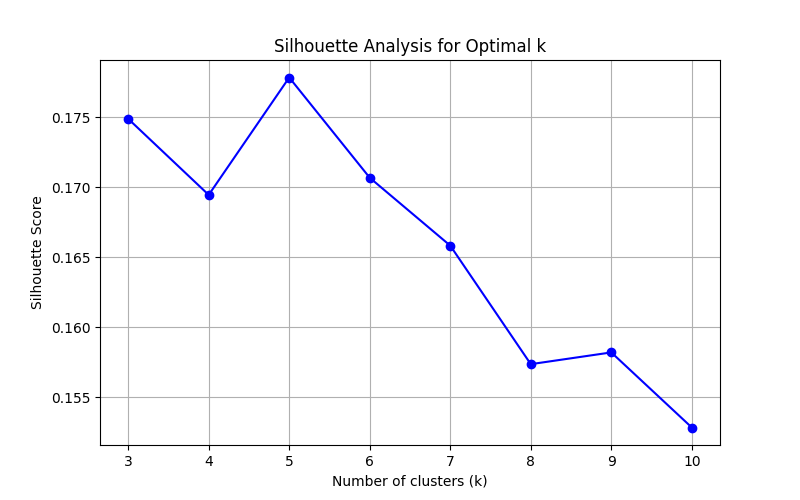

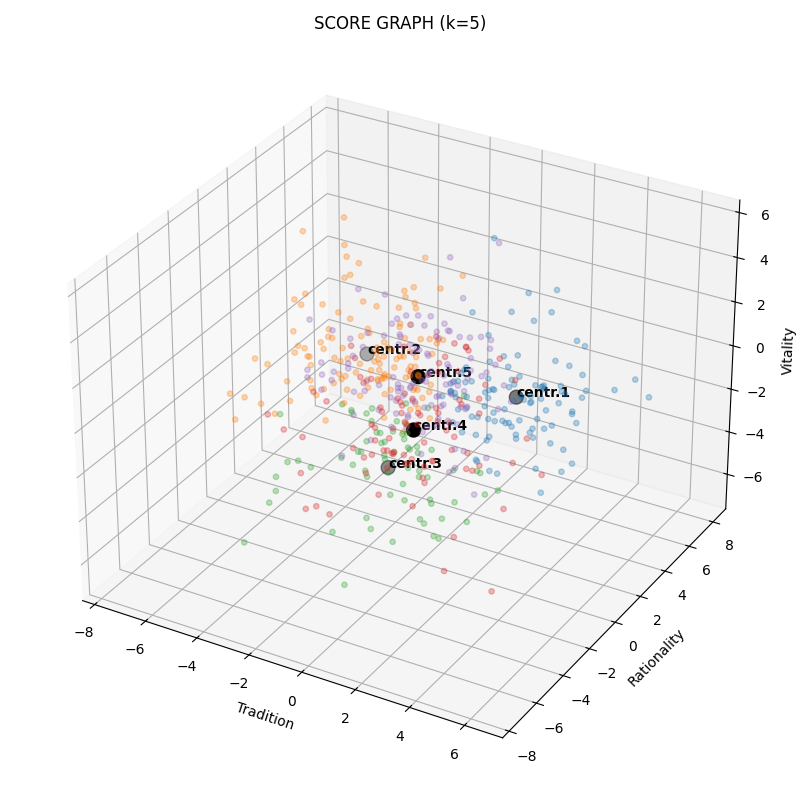

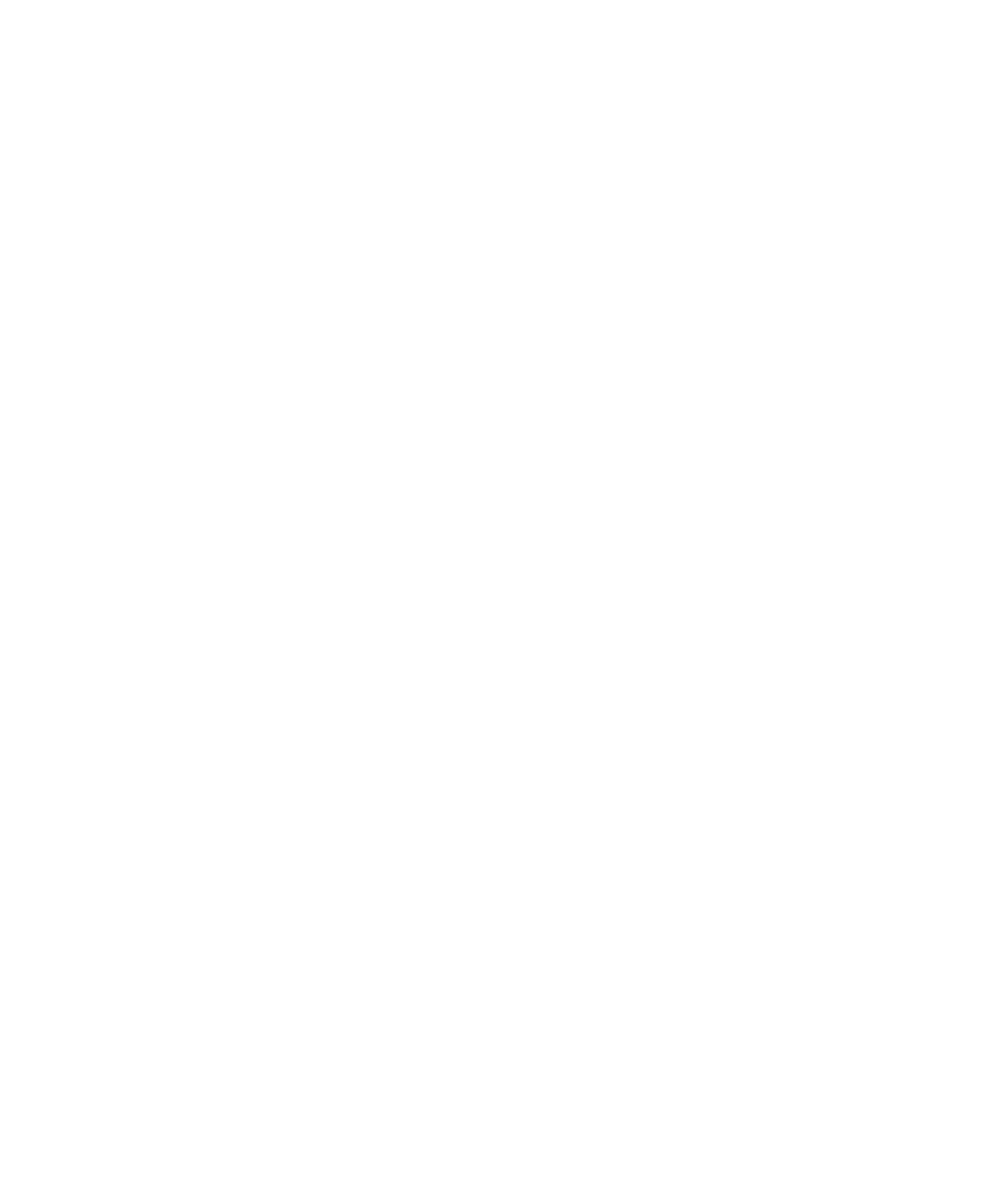

In [10]:
m = -np.inf
k_range = range(3, 11)
k_best = 0
silhouette_scores = []  

for k in k_range:
    print(f'k={k}:')
    km = KMeans(n_clusters=k, random_state=random_seed)
    km.fit(responses_ft_pca)
    
    silcoeff = silhouette_score(responses_ft_pca, km.labels_)
    silhouette_scores.append(silcoeff) # Store the score
    
    if silcoeff > m:
        k_best = k
        m = silcoeff

    print(f'   Silhouette Score: {silcoeff:.4f}')

print('\n')
print(f'Best k = {k_best} with score: {m:.4f}')


plt.figure(figsize=(8, 5))
plt.plot(k_range, silhouette_scores, marker='o', linestyle='-', color='b')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Analysis for Optimal k')
plt.grid(True)
plt.xticks(k_range) 
plt.show()


cmap = plt.cm.tab10 
km = KMeans(n_clusters=k_best, random_state=random_seed)
km.fit(responses_ft_pca)
sg_3d_km = plt.figure(figsize=(8, 8))
ax_3d_km = sg_3d_km.add_subplot(111, projection='3d')
ax_3d_km.scatter(responses_ft_pca[:, 0], responses_ft_pca[:, 1], responses_ft_pca[:, 2], s=15, c=cmap(km.labels_), alpha=0.3)

ax_3d_km.scatter(
    km.cluster_centers_[:, 0],
    km.cluster_centers_[:, 1],
    km.cluster_centers_[:, 2],
    c='black',
    s=100, 
    marker='o' 
)

for kk in range(k_best):
    ax_3d_km.text(
        km.cluster_centers_[kk, 0],
        km.cluster_centers_[kk, 1],
        km.cluster_centers_[kk, 2],
        f'centr.{kk + 1}',
        fontsize=10,
        fontweight='bold'
    )

ax_3d_km.set_title(f'SCORE GRAPH (k={k_best})')
ax_3d_km.set_xlabel(pc_names[0])
ax_3d_km.set_ylabel(pc_names[1])
ax_3d_km.set_zlabel(pc_names[2])
plt.grid(True, linestyle='--', linewidth=0.5, alpha=0.7)
plt.tight_layout()
plt.show()

maxs_y = responses_ft_pca.max(axis=0)
mins_y = responses_ft_pca.min(axis=0)

ncols = 2
nrows = int(np.ceil(k_best / ncols))
fig_centroids, ax_centroids = plt.subplots(nrows, ncols, figsize=(10, 4*nrows))

for ii in range(k_best):
    ir = ii // ncols
    ic = ii % ncols
    
    cluster_color = cmap(ii)

    ax_centroids[ir, ic].bar(np.arange(km.cluster_centers_.shape[1]), maxs_y, color='gray', alpha=0.1)
    ax_centroids[ir, ic].bar(np.arange(km.cluster_centers_.shape[1]), mins_y, color='gray', alpha=0.1)

    ax_centroids[ir, ic].bar(
        np.arange(km.cluster_centers_.shape[1]),
        km.cluster_centers_[ii, :],
        color=cluster_color, 
        alpha=0.9
    )

    ax_centroids[ir, ic].set_xticks(ticks=np.arange(km.cluster_centers_.shape[1]))
    ax_centroids[ir, ic].set_xticklabels(labels=pc_names, rotation=45)
    ax_centroids[ir, ic].grid(True, linestyle='--', linewidth=0.5, alpha=0.7)
    
    ax_centroids[ir, ic].set_title(f'CENTROID {ii + 1}', color=cluster_color, fontweight='bold')

total_slots = nrows * ncols
for i in range(k_best, total_slots):
    ir = i // ncols
    ic = i % ncols
    ax_centroids[ir, ic].axis('off')

plt.tight_layout()
plt.show()

#### For each Centroid, write the name you assigned to it and a brief interpretation that motivate the choice by exploiting the PC names(max 100 words per centroid):

 Centroid 1 - __Method__: We noticed positive values for the "Tradition" and "Rationality" PCs alongside a slightly positive value for "Reflection", while we can observe negative values for "Vitality" and "Rebellion", so this cluster describes people with rigor and a conservative way to see their life. They tend to stick to conventional actions and prefer methodical ones, thus we name the cluster "Method"


Centroid 2 -  __Pragmatism__: A negative value for "Tradition" alongside a positive value for "Rationality" may indicate people that are very practical, that prefers the most concrete aspects of life and have an opposition towards theoretical beliefs or passions. These are people characterized mostly by their "Pragmatism" 


Centroid 3 - __Gloom__: Considering a vey low value of "Vitality", but even negative values of "Tradition" and "Rationality", alongside a positive value for "Rebellion" we can describe these people as the ones who are in a depressive state in which they want to change their lives (indicated by their rebellious side) but they don't have the energy to do so, thus we name this cluster "Gloom"


Centroid 4 - __Simplicity__ : Negative values of "Rationality" and "Rebellion" but even "Reflection" and positive for "Tradition" may indicate those people who in general don't bother themselves about the world around them, also the fact that we have a perfectly 0 value for "Vitality" we can conclude that these people haven't enthusiasm about life, living it in "Simplicity"


Centroid 5 - __Romance__ : Positive values for "Vitality", "Rebellion" and "Tradition" alongside a negative one for "Rationality" indicate people with their heads in the clouds, hoping in their fairy-tale and escaping from their reality: "Romance" is the center of their life

## Exercise 5. Cluster External Evaluations

In this exercise, you have to do the following operations:
1. Select a subset meaningful labels for performing an external evaluation of the clustering results.
1. For each selected label, visualize the distribution of the label in each cluster and in the whole dataset.
1. Visualize the score graph with dots colored with respect to the label value; then, visualize the clusters in separated score-graphs, coloring the points according to the label values.


#### List the Labels you consider meaningful for an external cluster evaluation and motivate your choice (max 50 words per label):

Label 1 - __Age__: The age of a person is one of the greatest indicators for understanding better the custom and the routine of a generational breakpoint but even the point of view of a determinate epoch.

Label 2 - __Gender__: Obviously we can individuate gender-based preferences and those may allow us to understand better whether the clusters are related to demographic factors, although there is low variety in the outputs.

Label 3 - __Education__: The instruction of a person it's a good indicator because it has different ordered levels (from pupil to master degree) and so it gives us a more discriminating power across all the clusters.


#### Write the code for the visualizations cited in item 2 above:

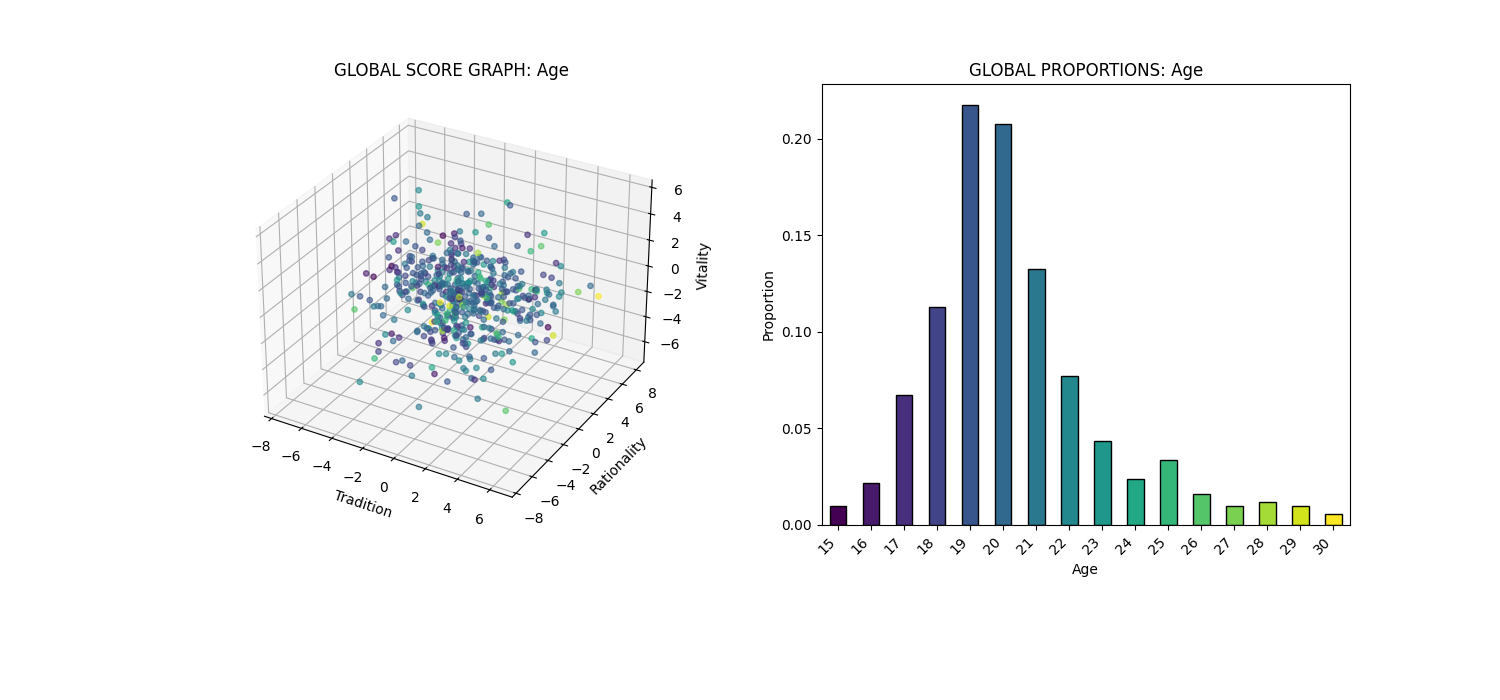

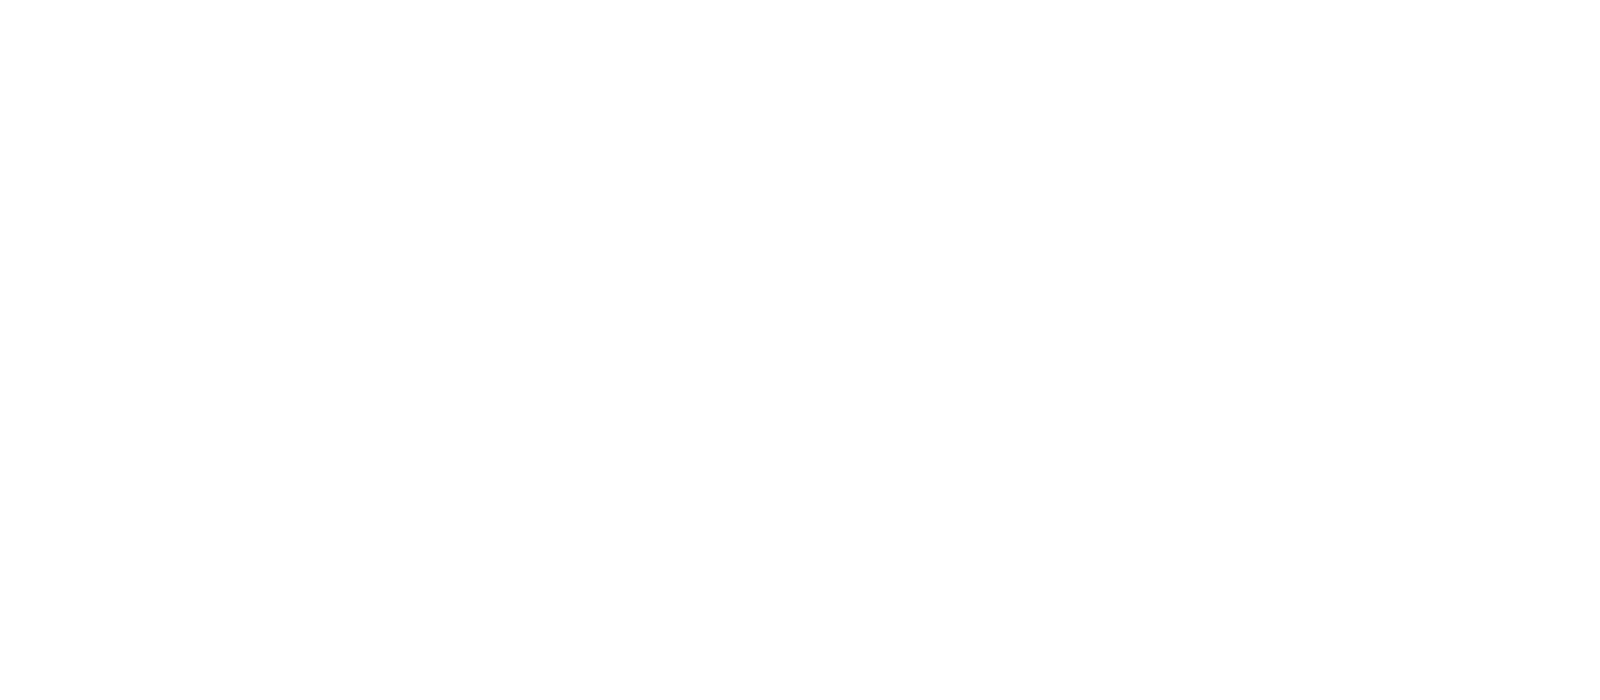

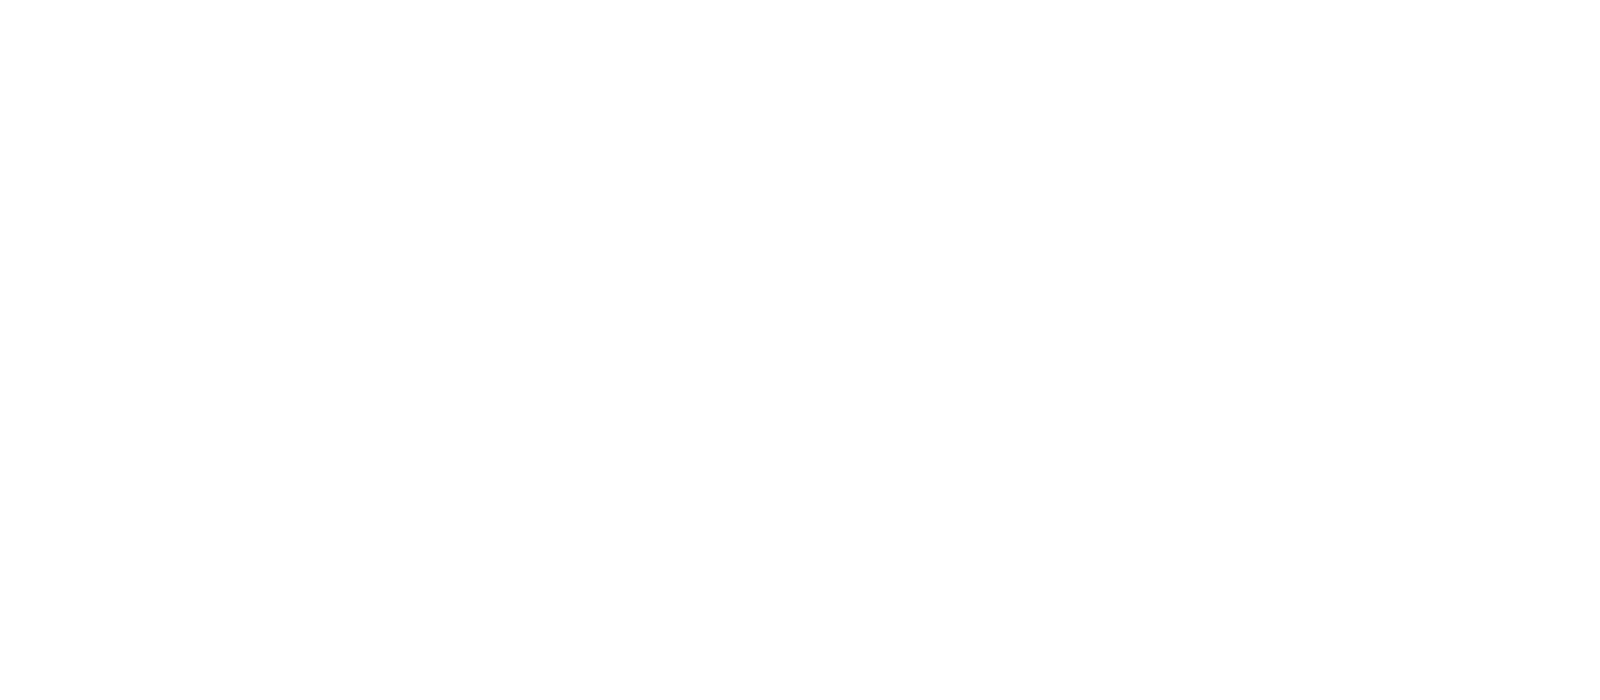

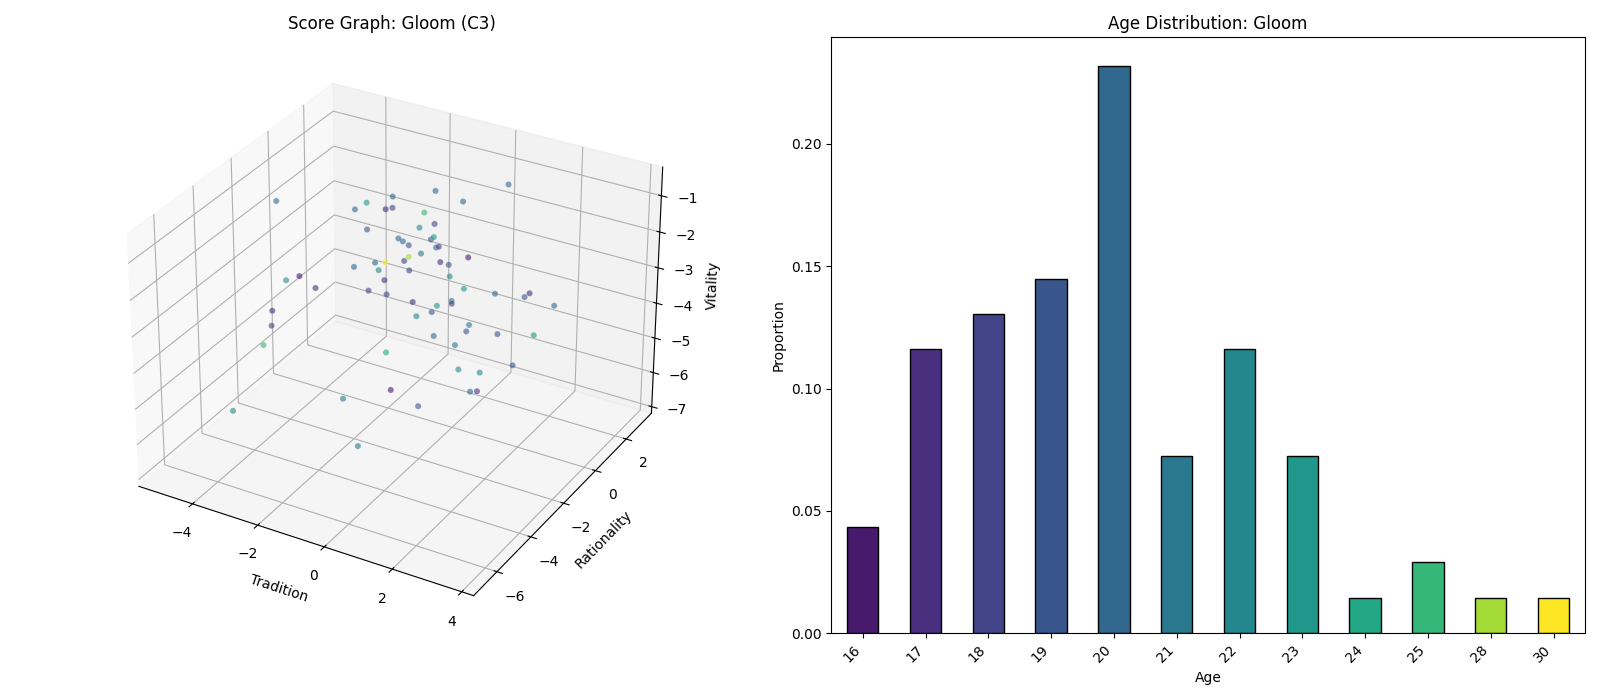

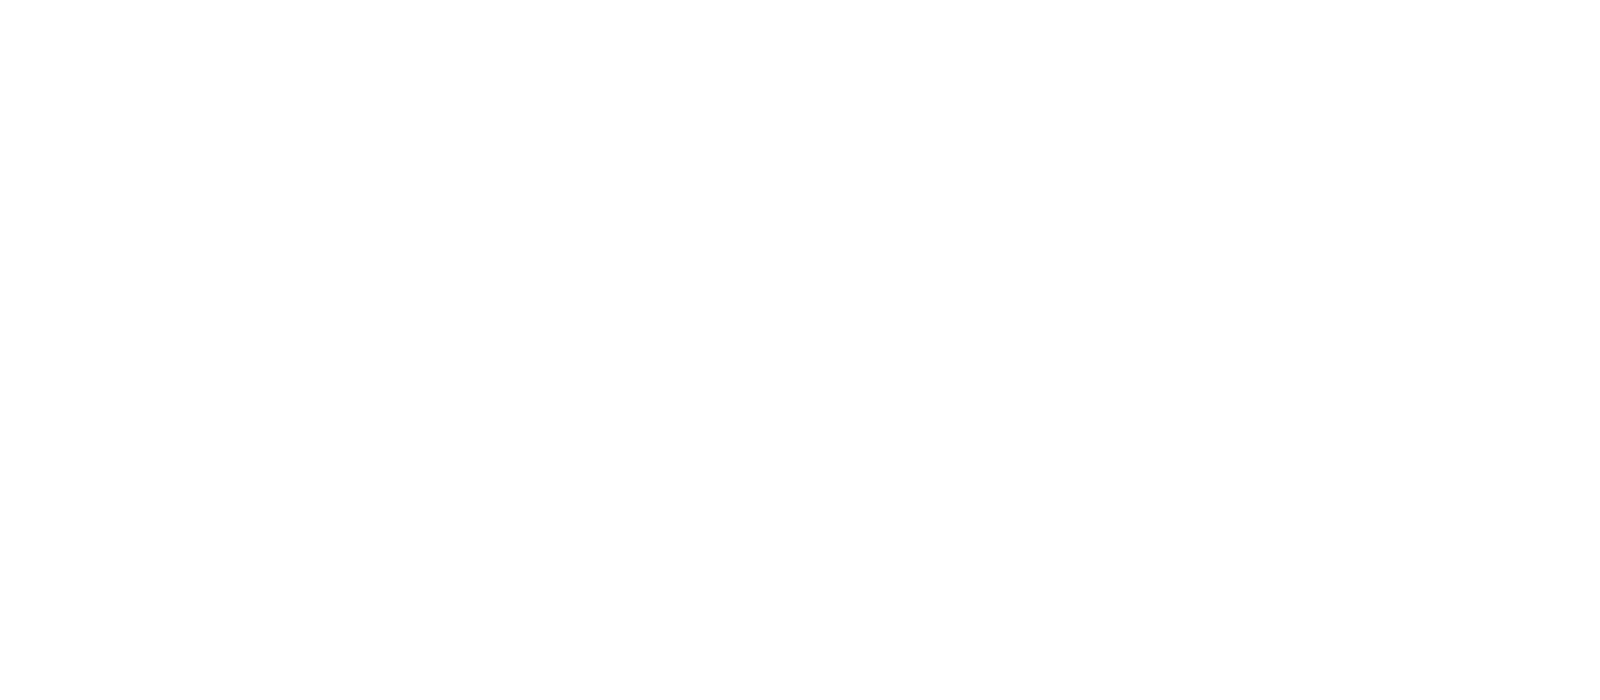

C:\Users\davep\AppData\Local\Temp\ipykernel_35920\1773471298.py:54: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig_cluster = plt.figure(figsize=(16, 7))


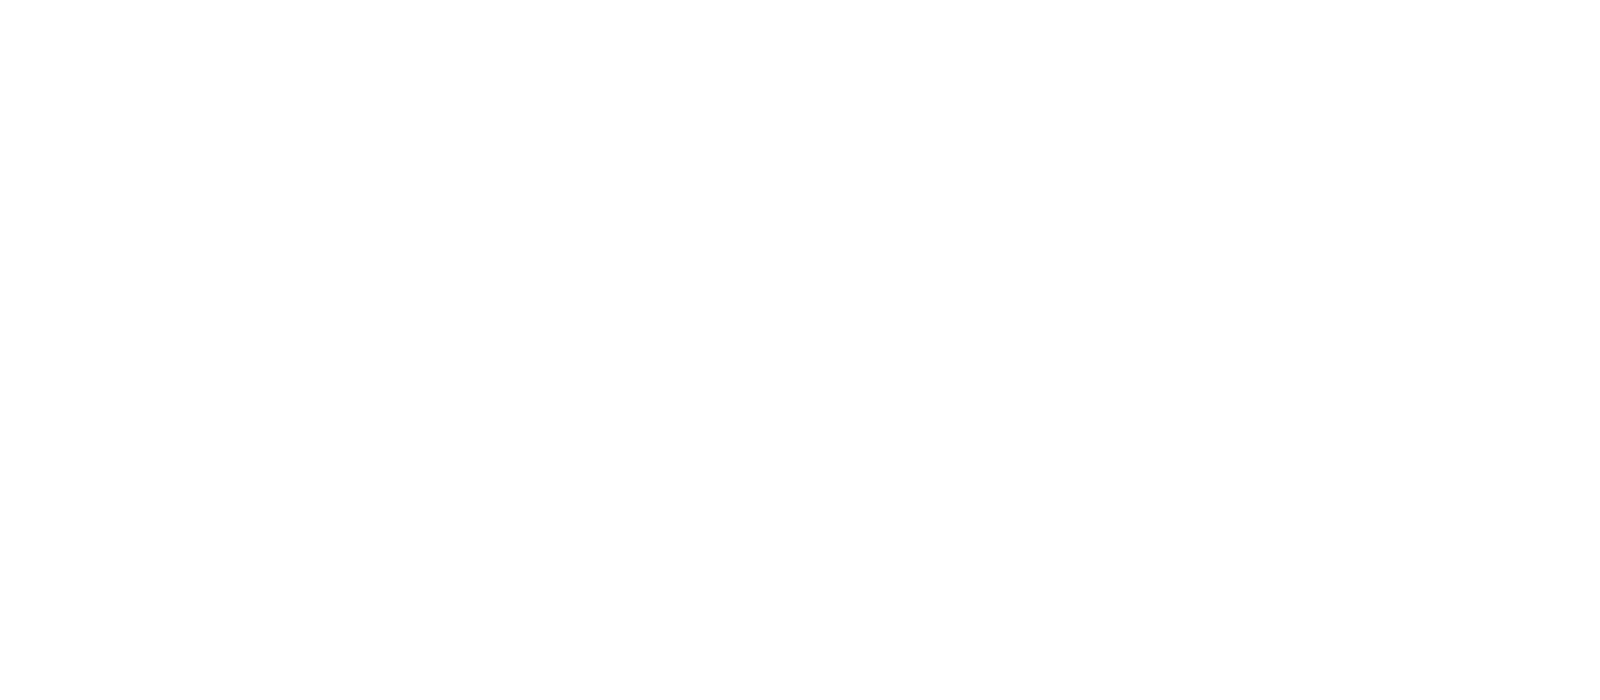

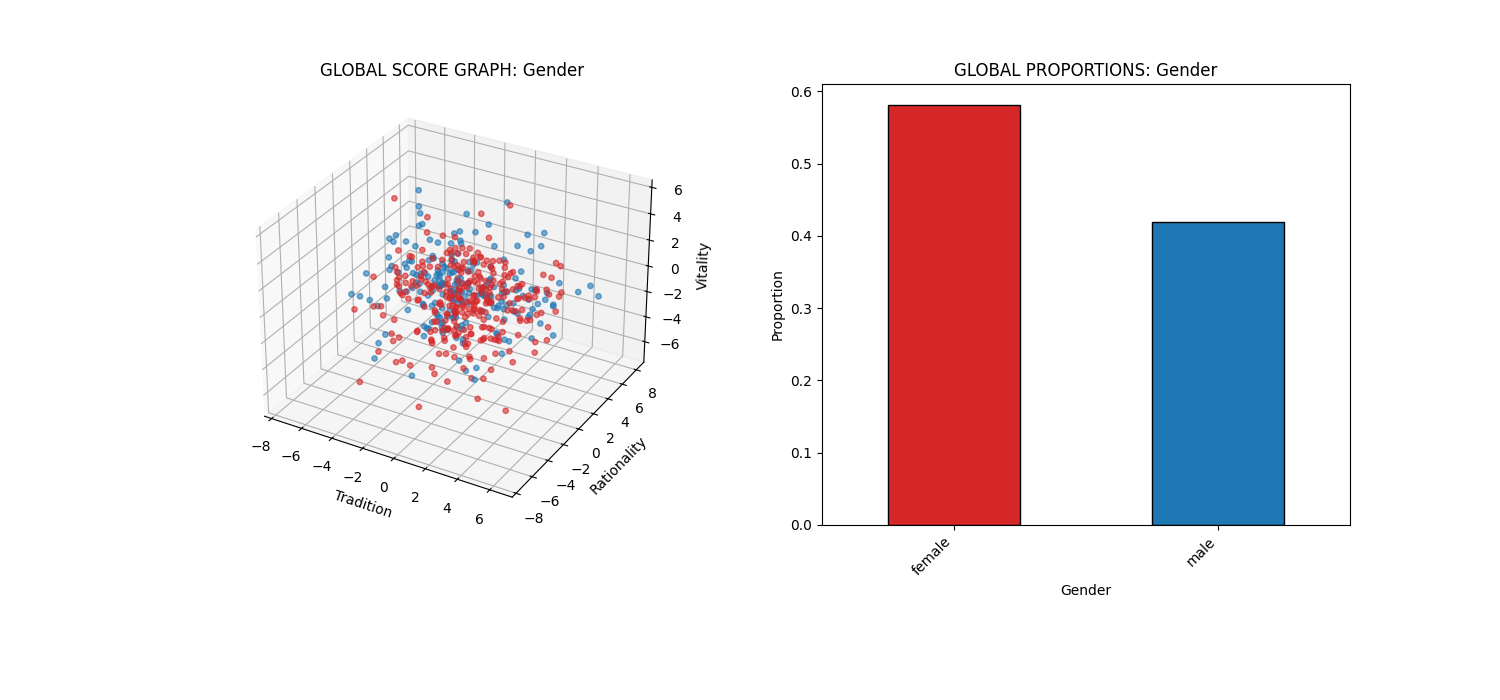

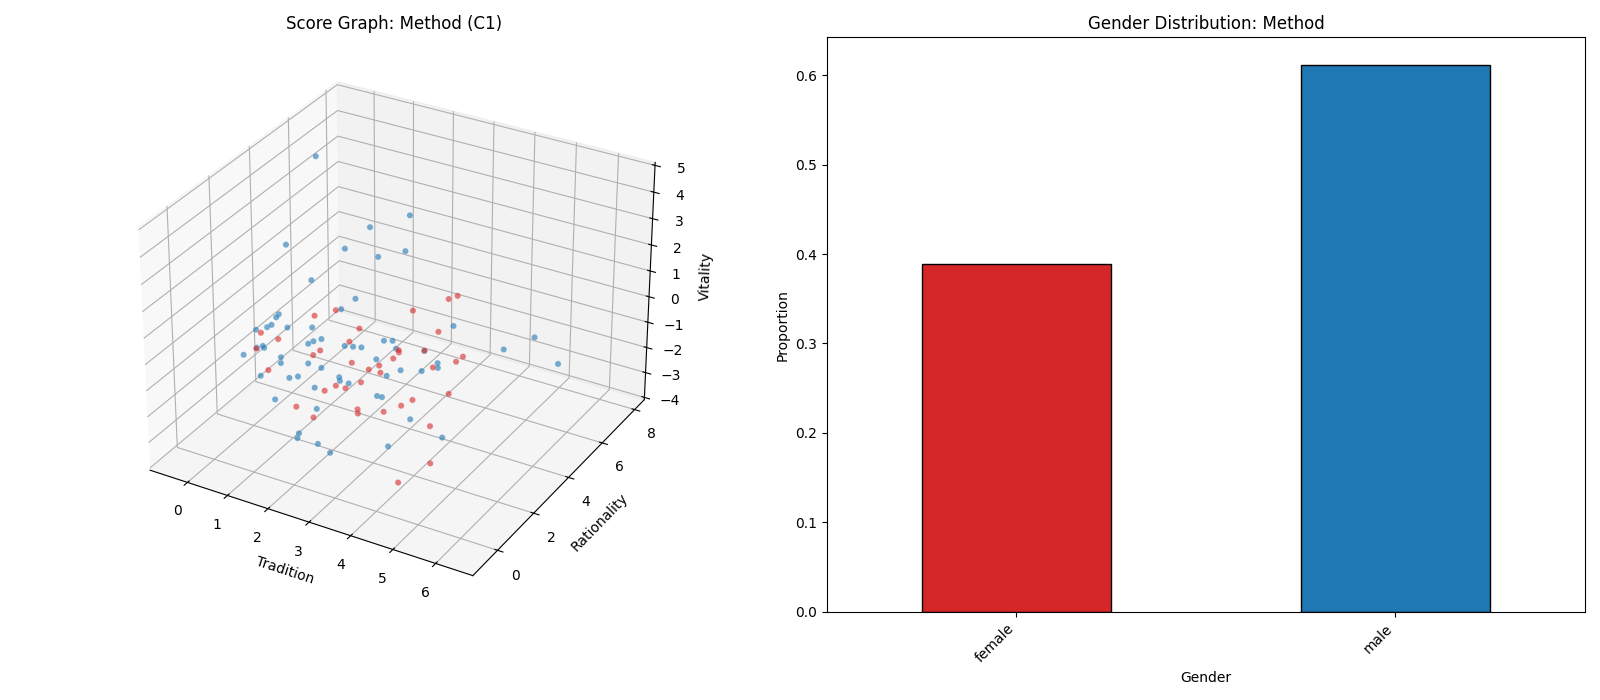

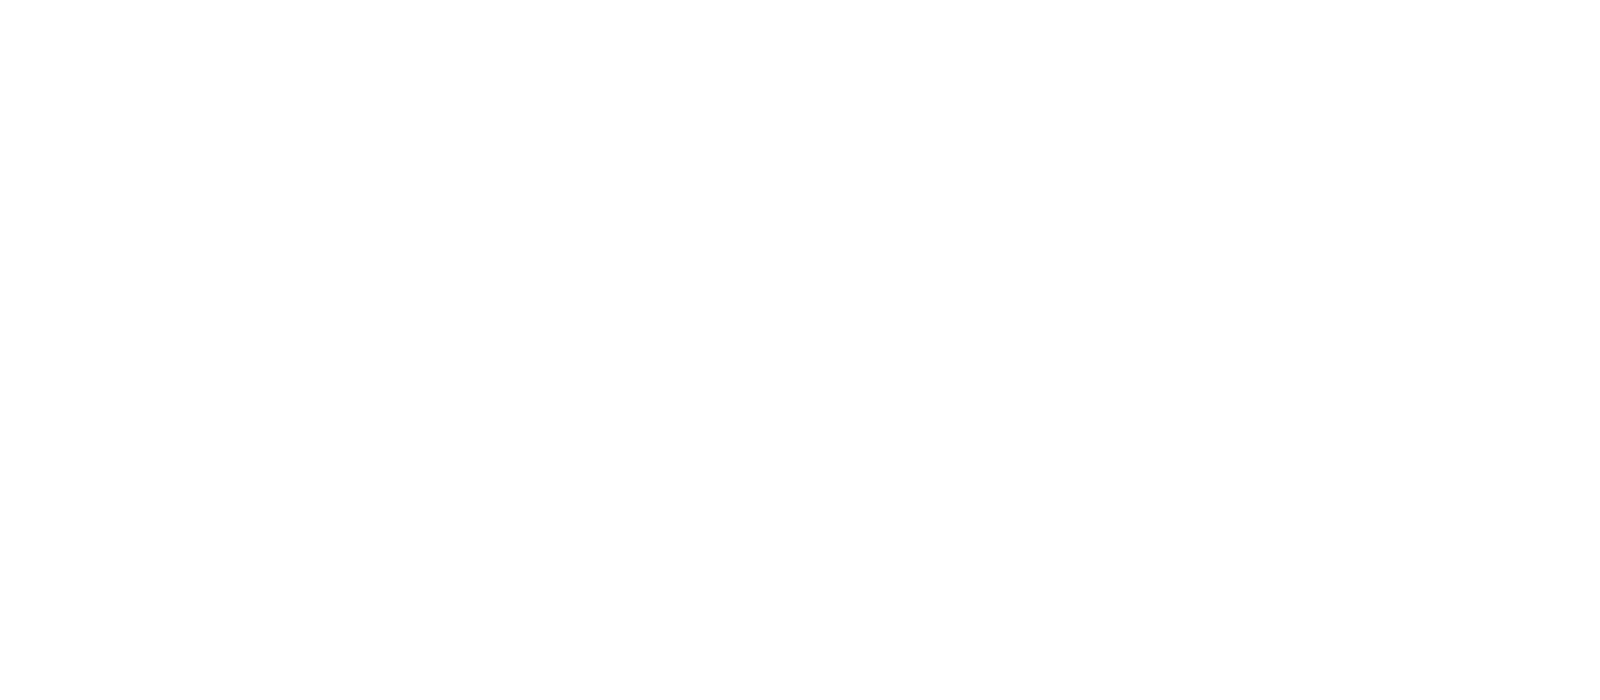

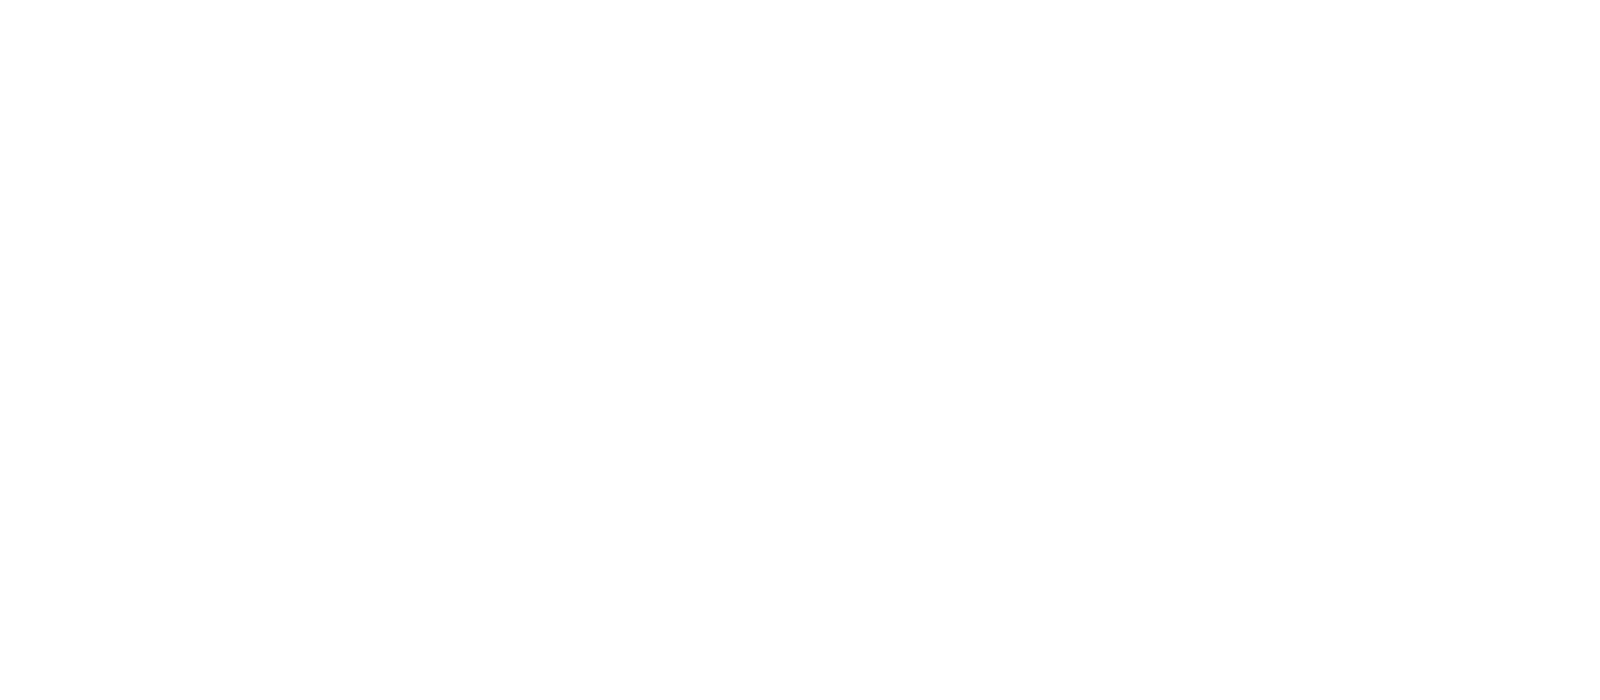

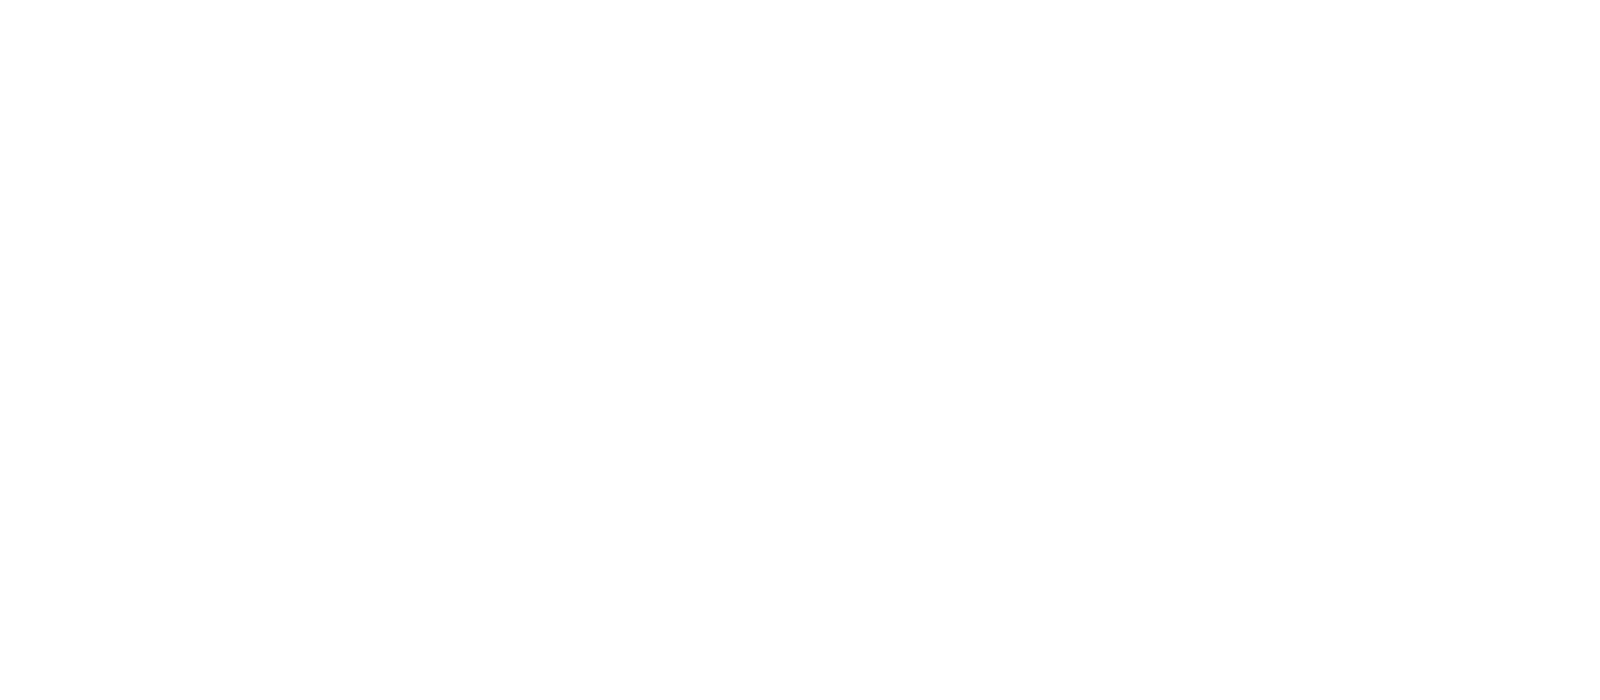

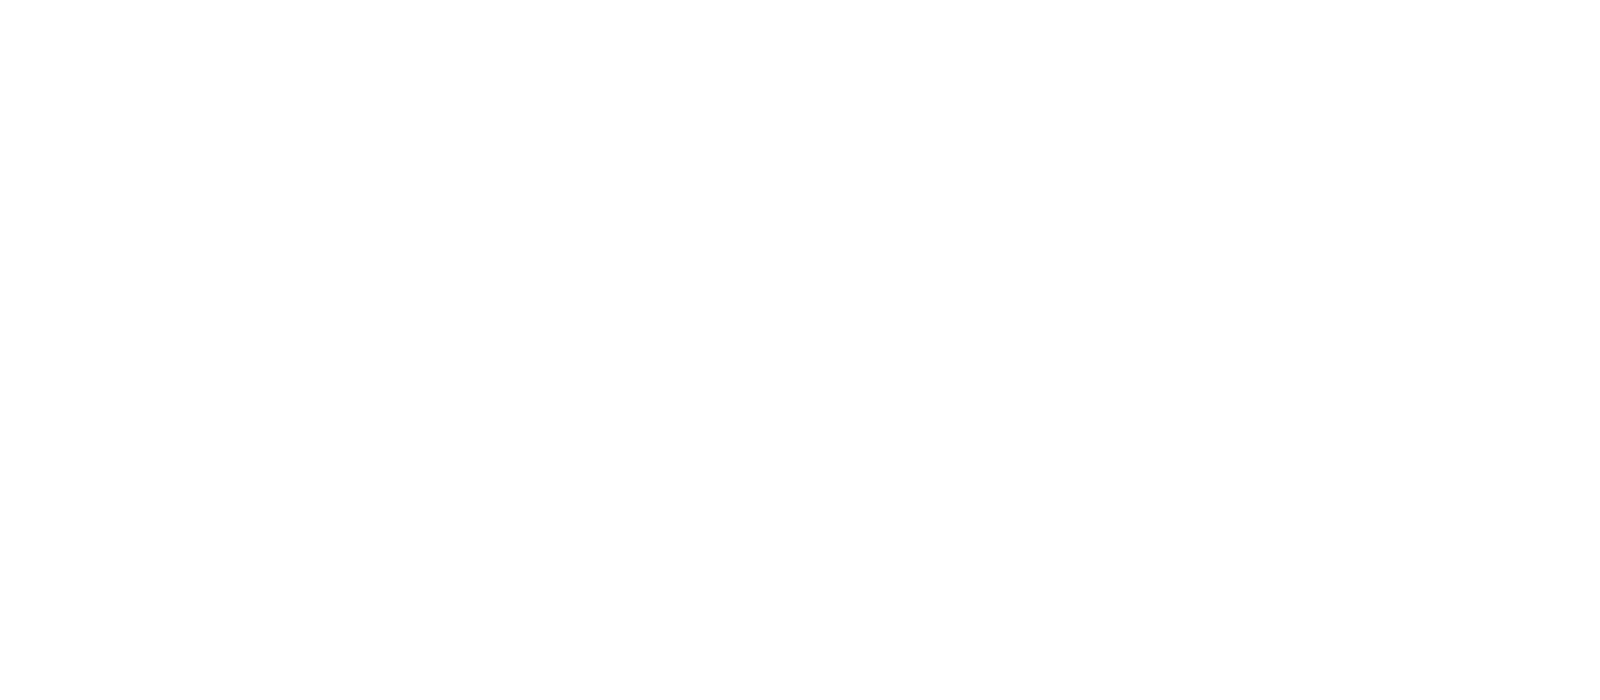

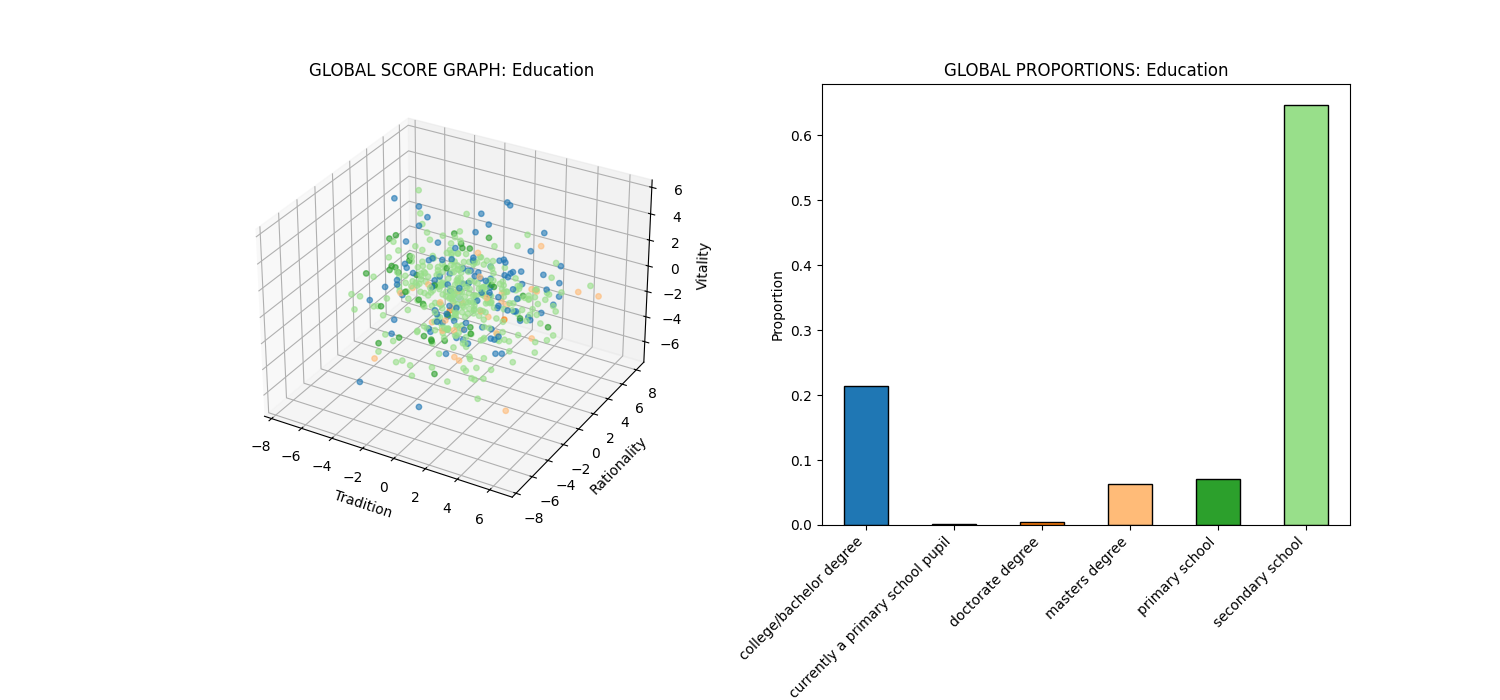

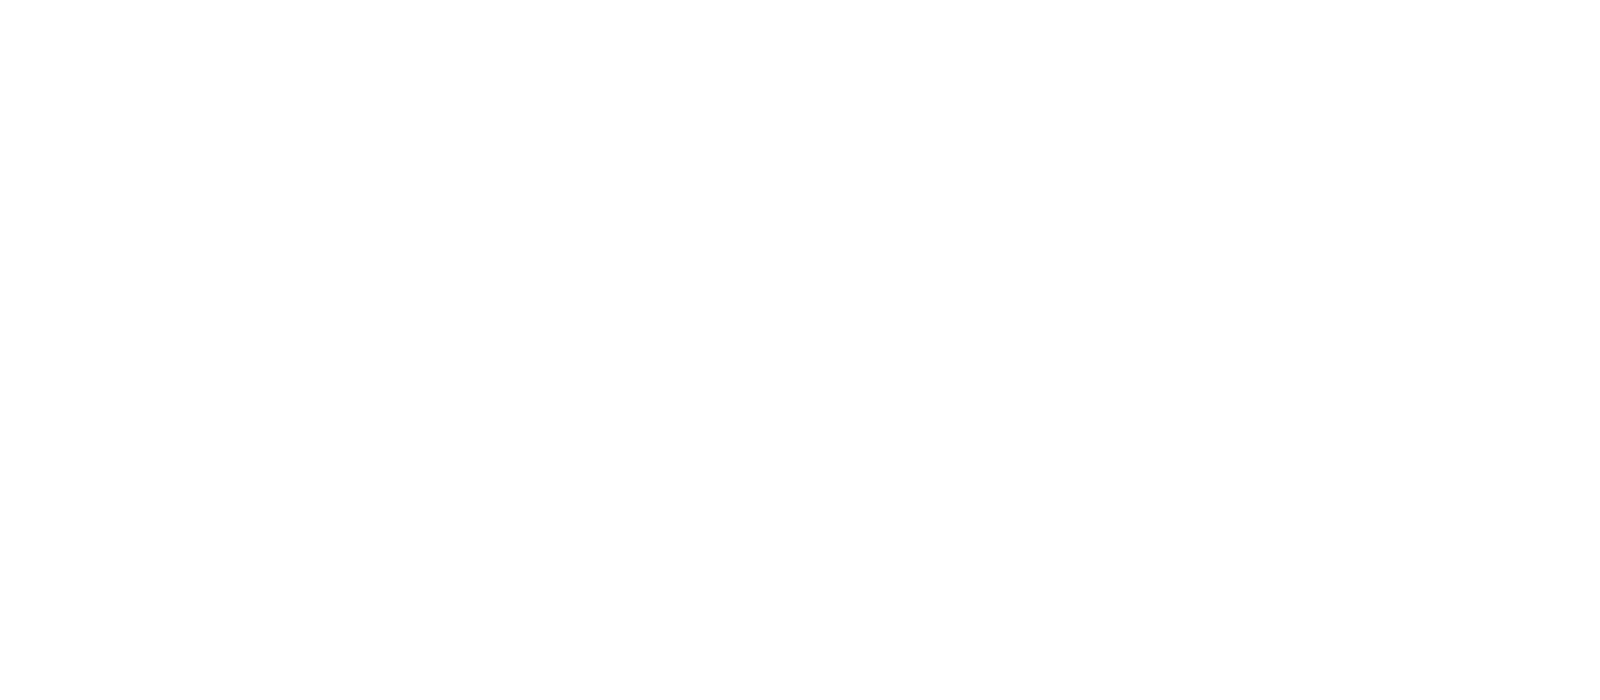

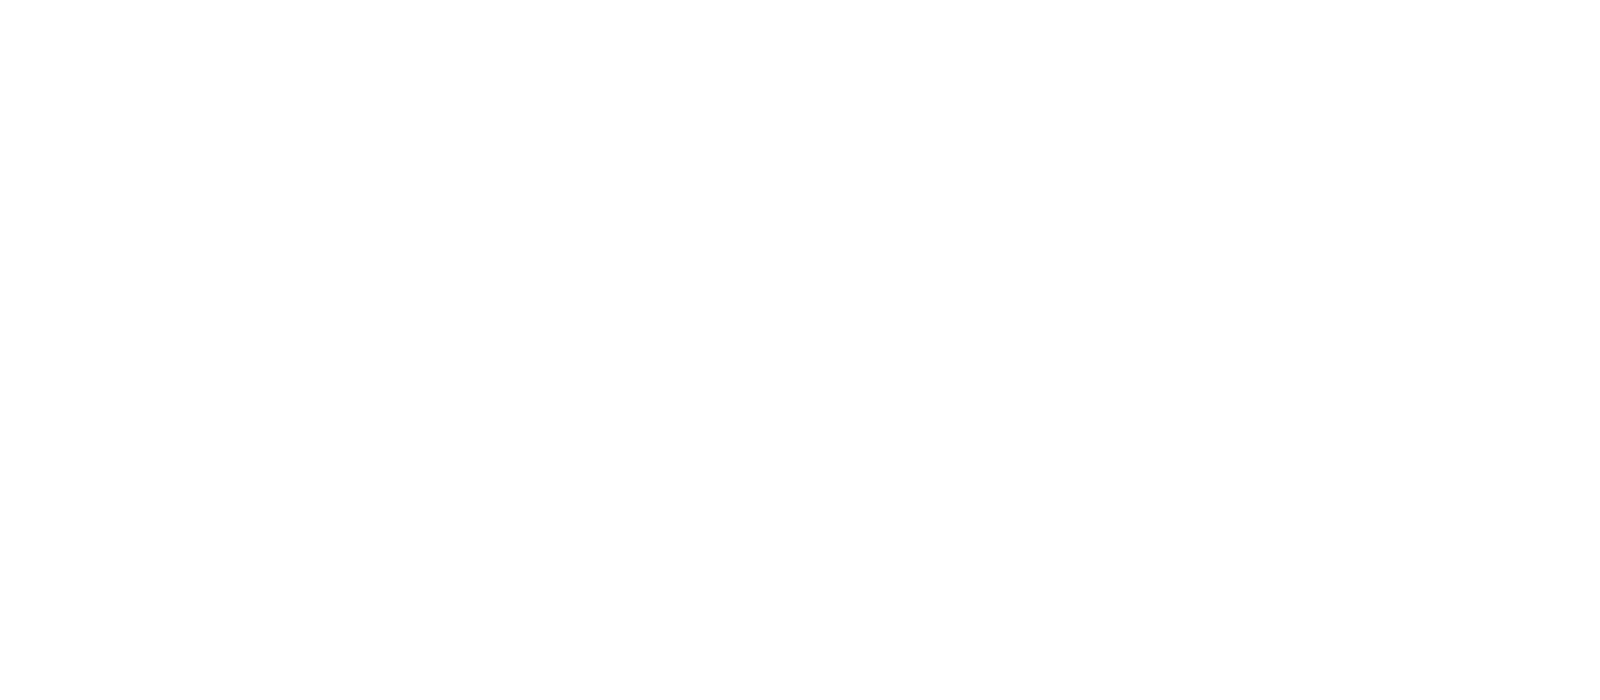

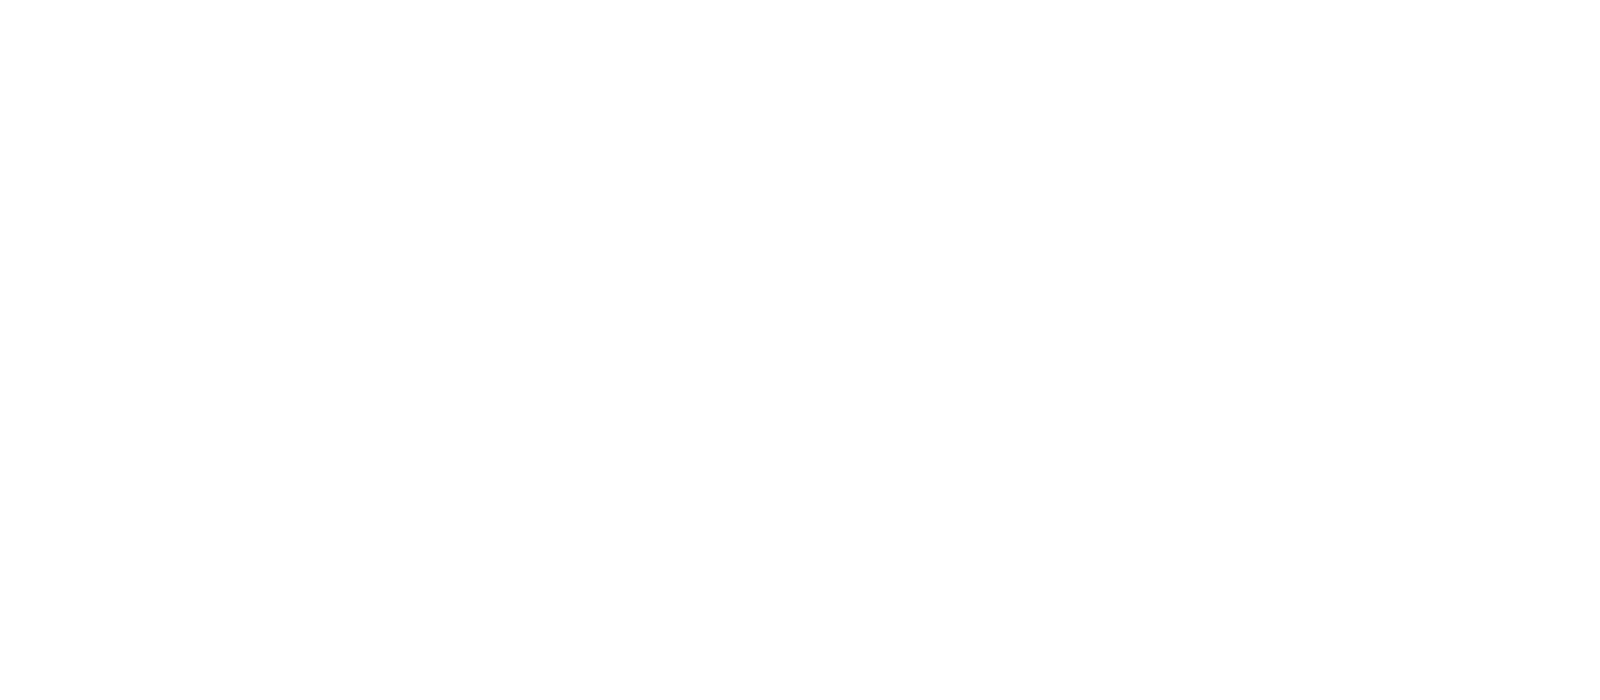

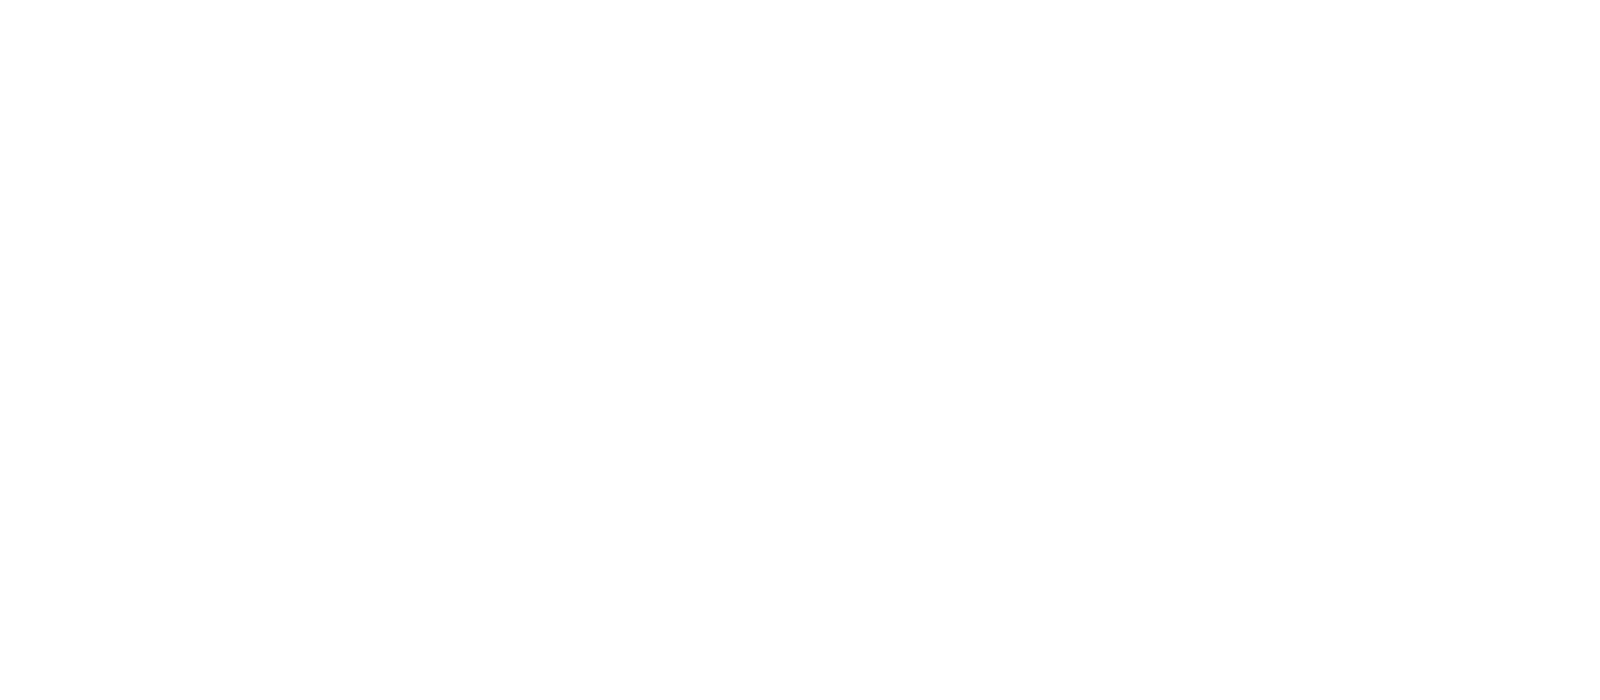

C:\Users\davep\AppData\Local\Temp\ipykernel_35920\1773471298.py:81: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


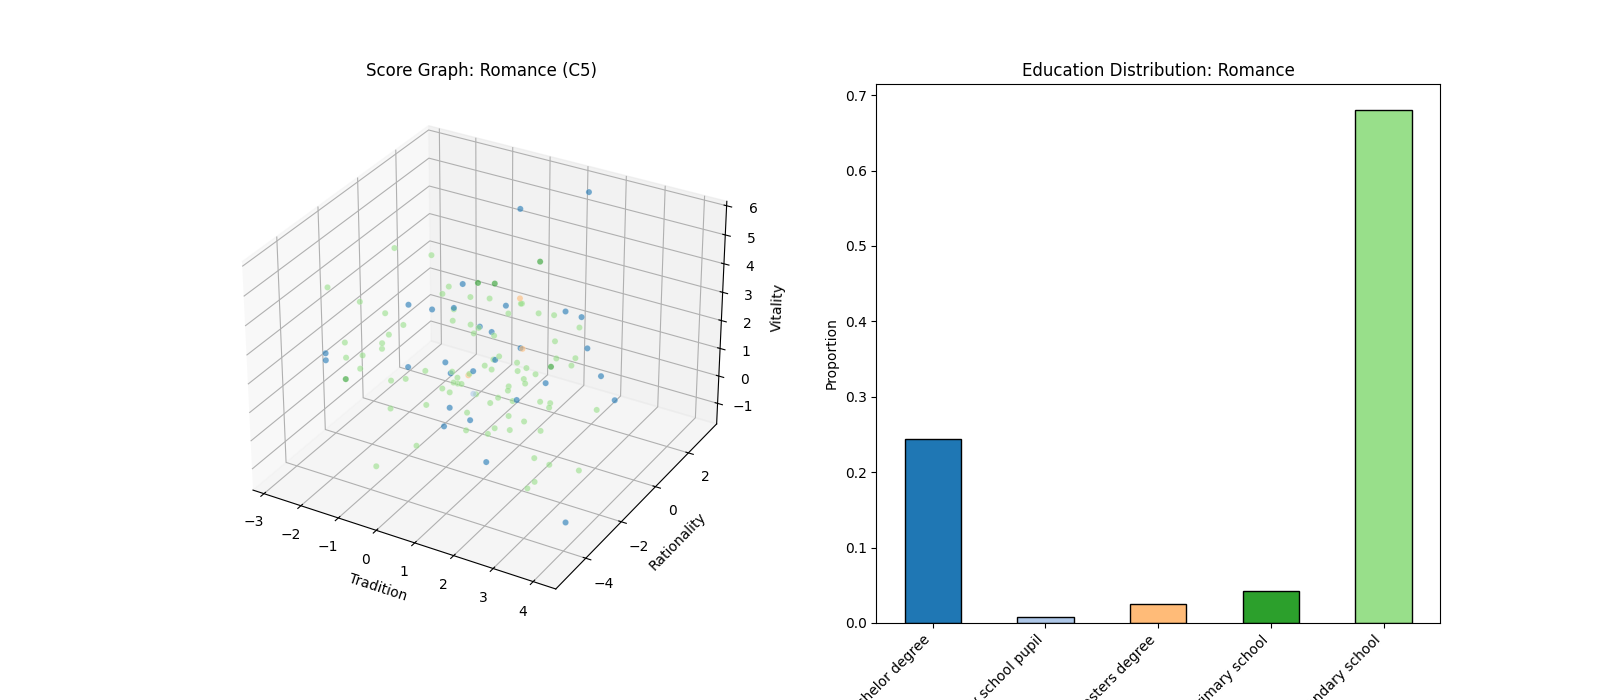

In [11]:
selected_labels = ['Age', 'Gender', 'Education']
centroid_names = ['Method','Pragmatism','Gloom','Simplicity','Romance']

gender_colors = {'male': '#1f77b4', 'female': '#d62728'} 

responses_lb = responses_lb.copy()
responses_lb['cluster'] = km.labels_

for label in selected_labels:
    lb_values = np.sort(responses_lb[label].unique())
    label_to_color = {}

    if label == 'Gender':
        for val in lb_values:
            label_to_color[val] = gender_colors.get(val, 'gray')
    
    elif label == 'Age':
        cmap = matplotlib.colormaps.get_cmap('viridis')
        norm = plt.Normalize(vmin=lb_values.min(), vmax=lb_values.max())
        for val in lb_values:
            label_to_color[val] = cmap(norm(val))
            
    else: 
        cmap = matplotlib.colormaps.get_cmap('tab20')
        for i, val in enumerate(lb_values):
            label_to_color[val] = cmap(i % 10)

    color_scat_global = [label_to_color[val] for val in responses_lb[label].values]

    fig_global = plt.figure(figsize=(15, 7)) 
    
    ax1 = fig_global.add_subplot(1, 2, 1, projection='3d')
    ax1.scatter(responses_ft_pca[:, 0], responses_ft_pca[:, 1], responses_ft_pca[:, 2], s=15, c=color_scat_global, alpha=0.6)
    ax1.set_title(f'GLOBAL SCORE GRAPH: {label}')
    ax1.set_xlabel(pc_names[0])
    ax1.set_ylabel(pc_names[1])
    ax1.set_zlabel(pc_names[2])
    
    ax2 = fig_global.add_subplot(1, 2, 2)
    counts = responses_lb[label].value_counts(normalize=True).sort_index()
    bars = counts.plot(kind='bar', ax=ax2, edgecolor='black')
    for i, patch in enumerate(bars.patches):
        patch.set_facecolor(label_to_color[counts.index[i]])
    
    ax2.set_title(f'GLOBAL PROPORTIONS: {label}')
    ax2.set_ylabel('Proportion')
    
    
    plt.xticks(rotation=45, ha='right')
    plt.subplots_adjust(bottom=0.25) 
    plt.show()

    for k in range(k_best):
        fig_cluster = plt.figure(figsize=(16, 7))
        
        
        ax_3d = fig_cluster.add_subplot(1, 2, 1, projection='3d')
        idx = np.where(km.labels_ == k)[0]
        cluster_colors = [color_scat_global[i] for i in idx]
        
        ax_3d.scatter(responses_ft_pca[idx, 0], responses_ft_pca[idx, 1], responses_ft_pca[idx, 2], s=20, c=cluster_colors, alpha=0.6, edgecolor='w', linewidth=0.2)
        ax_3d.set_title(f'Score Graph: {centroid_names[k]} (C{k+1})')
        ax_3d.set_xlabel(pc_names[0])
        ax_3d.set_ylabel(pc_names[1])
        ax_3d.set_zlabel(pc_names[2])
        
        
        ax_bar = fig_cluster.add_subplot(1, 2, 2)
        cluster_data = responses_lb[responses_lb['cluster'] == k][label]
        c_counts = cluster_data.value_counts(normalize=True).sort_index()
        
        bars = c_counts.plot(kind='bar', ax=ax_bar, edgecolor='black')
        for i, patch in enumerate(bars.patches):
            patch.set_facecolor(label_to_color[c_counts.index[i]])
            
        ax_bar.set_title(f'{label} Distribution: {centroid_names[k]}')
        ax_bar.set_ylabel('Proportion')      
    
        plt.setp(ax_bar.get_xticklabels(), rotation=45, ha='right')
        
        plt.tight_layout()
        plt.show()

#### For each selected label, comment the results observed in the visualizations (max 100 words per label):

__Age__: At first we notice that there is a large portion of people between the age of 19 and 20. For the "Method" and "Pragmatism" clusters we don't notice a significant ratio change with respect to the global distribution, however that doesn't apply for the other clusters: for "Gloom" and "Simplicity" we have a more "mature" ratio of the people and that makes sense considering that they are either struggling with their life or they are already free from any imposed constraint, while for "Romance" we have a younger partition of the survey depicting a more carefree portion of young people.

__Gender__: We observe a larger presence of females rather than males in the global distribution. Made exception for "Gloom" that have basically a 50:50 ratio, we notice that "Method" and "Pragmatism" have larger ratios for the male part of the survey while "Simplicity" and "Romance" for the female one, highlighting that in the Slovakian young society the former are mostly focused on the rational aspects of life, while the latter are more laid-back and cheerful.

__Education__: The survey is taken on students and their friends, so it is obvious that we have the secondary school diploma as the most present education level. On "Method" we notice a larger number of people with a university degree than "Pragmatism" indicating that people with an higher education level tend to be more logical and less practical. We can also notice a larger proportion of people with respect to the global proportion in the category "Gloom" are the ones with a degree or the ones with a primary school degree, remarking the fact that they can have problems either with the world of work or the difficulties related to being in school.   

## Exercise 6. Cluster Internal Evaluations

In this exercise, you have to do the following operations:
1. For each cluster, measure the corresponding average silhouette score
1. Visualize the silhouette of the clusters and the general one of the clustering and compare them


#### Write the code for computing the silhouette scores and for visualizing them:

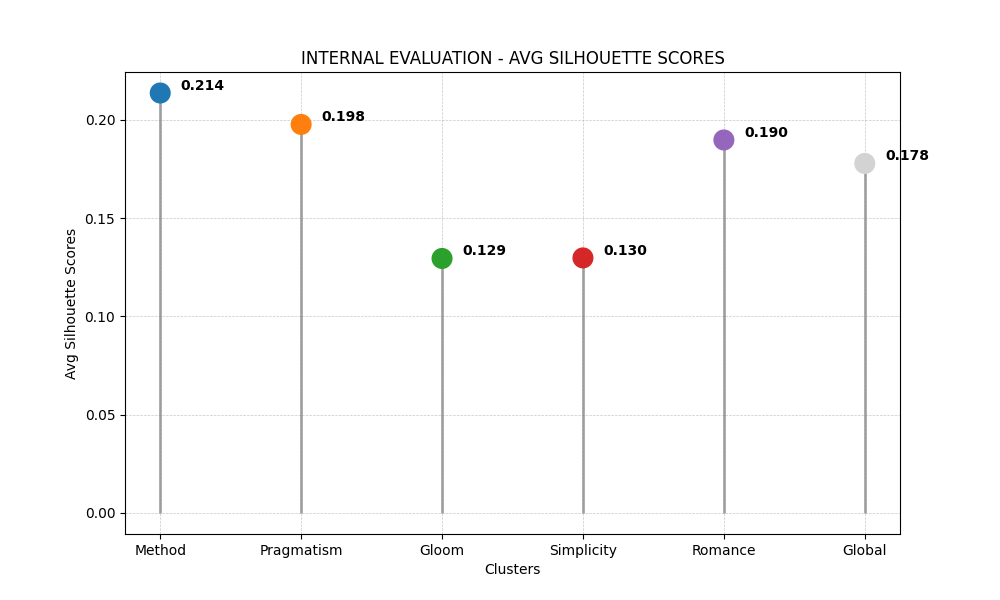

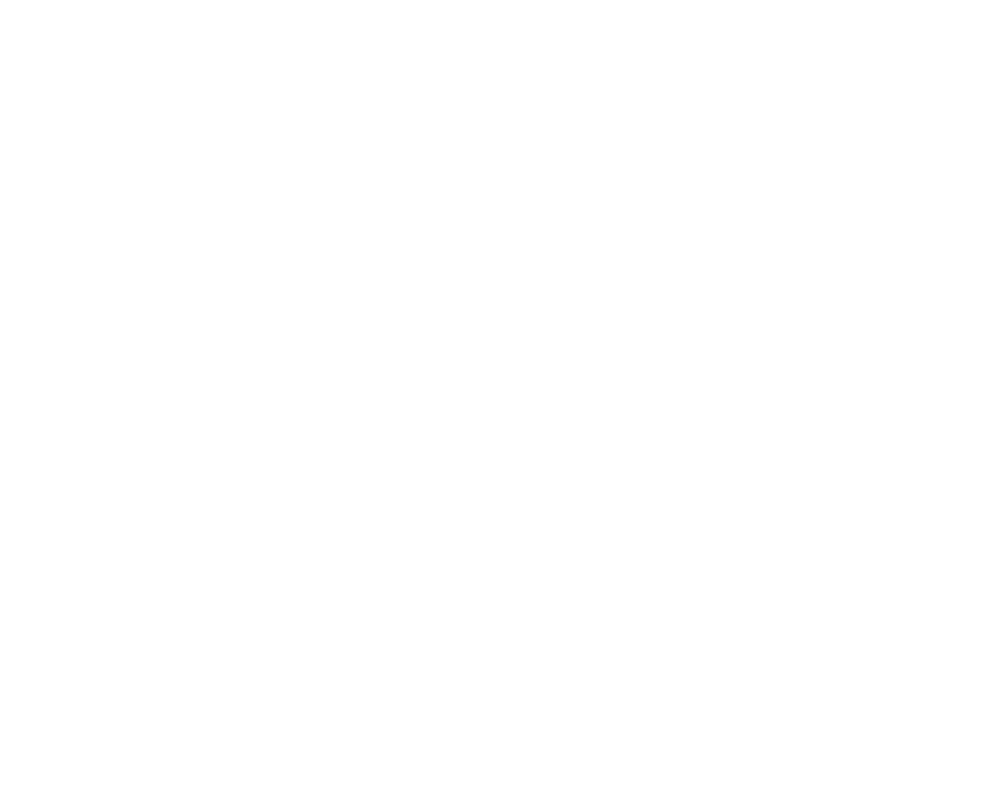

In [21]:
silscores = silhouette_samples(responses_ft_pca, km.labels_)
m = np.mean(silscores)
cluster_silscores = [np.mean(silscores[km.labels_ == kk]) for kk in range(k_best)]

silcoeffs_df = pd.DataFrame(
    np.array(cluster_silscores + [m]),
    index = centroid_names + ['Global'],
    columns = ['Sil. Score']
)

plt.figure(figsize=(10, 6))
colors = [plt.cm.tab10(i) for i in range(k_best)] + ['lightgrey'] 

plt.vlines(x=silcoeffs_df.index.tolist(), ymin=0, ymax=silcoeffs_df['Sil. Score'].values, 
           color='gray', alpha=0.7, linewidth=2)
plt.scatter(silcoeffs_df.index.tolist(), silcoeffs_df['Sil. Score'].values, 
            color=colors, s=200, zorder=3)

for i, score in enumerate(silcoeffs_df['Sil. Score'].values):
    plt.text(
        x=i+0.3,               
        y=score,   
        s=f'{score:.3f}',  
        ha='center',       
        va='bottom',       
        fontweight='bold',
        fontsize=10
    )

plt.xlabel('Clusters')
plt.ylabel('Avg Silhouette Scores')
plt.title('INTERNAL EVALUATION - AVG SILHOUETTE SCORES')
plt.grid(True, linestyle='--', linewidth=0.5, alpha=0.7)

plt.show()

fig, ax = plt.subplots(figsize=(10, 8))
y_lower = 10 
for i in range(k_best):
    ith_cluster_sil_values = silscores[km.labels_ == i]
    ith_cluster_sil_values.sort()
    size_cluster_i = ith_cluster_sil_values.shape[0]
    y_upper = y_lower + size_cluster_i
    cluster_color = plt.cm.tab10(i) 
    ax.fill_betweenx(np.arange(y_lower, y_upper),
                      0, ith_cluster_sil_values,
                      facecolor=cluster_color, edgecolor='black', alpha=0.7)
    ax.text(-0.15, y_lower + 0.5 * size_cluster_i, centroid_names[i], 
            ha='right', va='center', fontsize=10, fontweight='bold')
    y_lower = y_upper + 10 

all_sil_values = silscores.copy()
all_sil_values.sort()

size_global = all_sil_values.shape[0]
y_upper = y_lower + size_global

ax.fill_betweenx(np.arange(y_lower, y_upper),
                  0, all_sil_values,
                  facecolor='lightgrey', edgecolor='black', alpha=0.7)

ax.text(-0.15, y_lower + 0.5 * size_global, 'Global', 
        ha='right', va='center', fontsize=10, fontweight='bold')

ax.set_title("SILHOUETTE ANALYSIS FOR KMEANS CLUSTERING")
ax.set_xlabel("Silhouette Coefficient")
ax.set_ylabel("Clusters")


ax.axvline(x=m, color="red", linestyle="--")
ax.text(m + 0.01, 10, f'Global Mean: {m:.3f}', color='red', fontweight='bold')
ax.grid(axis='x', linestyle=':', alpha=0.5)
ax.set_yticks([])

plt.tight_layout()
plt.show()

#### Comment the results, also considering the results observed previously (e.g., score graphs, centroids, etc. - max 150 words):

We've already had a Global Mean Silhouette Score of 0.178 and in the context of internal evaluation, such a score suggests a high degree of dimensional overlap and possibly noise within the dataset. The Method and Pragmatism clusters emerge as the best clusters, successfully partitioning the sample based on orientations toward both Tradition and Rationality.
On the other hand, the Gloom and Simplicity segments demonstrate boundary ambiguity. The presence of negative silhouette coefficients within these clusters indicates a misclassification where specific observations are closer to neighboring centroids than their assigned centers. While we can still identify different archetypes discussed earlier, as we can see with the high Vitality value in Romance or the negative Rationality in Simplicity, the modest silhouette mean suggests that these clusters are overlapping clouds rather than distinct ones (as we can see in the score graphs).